# Confidence analysis
## Three run-1 models: ResNet18 224, ResNet50 28 and original ViT; full test split

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

threshold, n_bins = 0.90, 10
model_names = ['resnet18', 'resnet50', 'vit']
class_names = list(json.loads(Path('data/metadata.json').read_text())['label'].values())
class_names[3] = 'immature granulocytes'
with np.load('data/bloodmnist.npz', allow_pickle=False) as data:
    images, labels = data['test_images'], data['test_labels'].ravel()
probabilities = []
for name in model_names:
    rows = np.loadtxt(f'predictions/{name}_test.csv', delimiter=',', skiprows=1)
    np.testing.assert_array_equal(rows[:, 0], np.arange(len(labels)))
    np.testing.assert_array_equal(rows[:, 1], labels)
    probabilities.append(rows[:, 3:])
probabilities = np.stack(probabilities)
np.testing.assert_allclose(probabilities.sum(-1), 1, atol=1e-6)
predicted = probabilities.argmax(-1)
confidence = probabilities.max(-1)
correct = predicted == labels
bins = np.linspace(0, 1, n_bins + 1)
centers = (bins[:-1] + bins[1:]) / 2

def bin_ids(values):
    return np.clip(np.searchsorted(bins, values, side='right') - 1, 0, n_bins - 1)

def entropy(p):
    p = np.asarray(p, dtype=float)
    return -(p * np.log(np.maximum(p, 1e-300))).sum(-1) / np.log(p.shape[-1])

uncertainty = entropy(probabilities)
print(f'{len(labels)} test images; high-confidence threshold: {threshold:.0%}')
from itertools import combinations
pairs = list(combinations(range(len(model_names)), 2))
model_colors = ['#2678ad', '#3b9956', '#c25a7c']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=model_colors)


3421 test images; high-confidence threshold: 90%


## Reliability diagram — equal-width confidence bins; ECE weighted by bin counts; empty bins omitted

resnet18: accuracy=96.61%, mean confidence=98.73%, ECE=0.0219
resnet50: accuracy=95.73%, mean confidence=98.66%, ECE=0.0298
vit: accuracy=96.99%, mean confidence=98.62%, ECE=0.0167


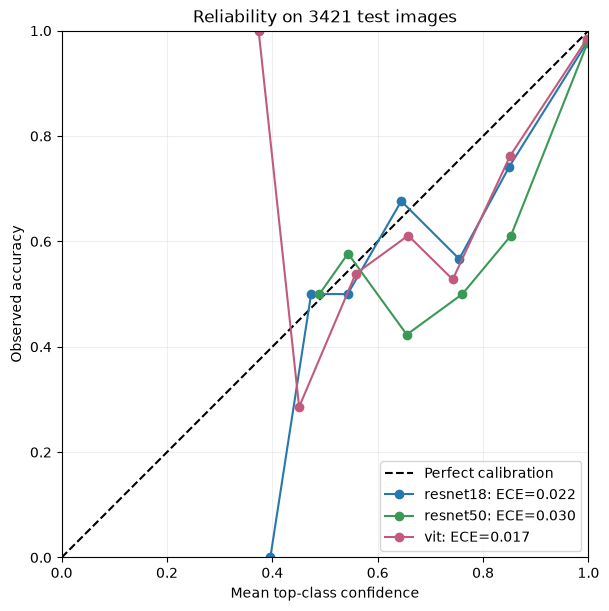

In [3]:
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
for m, name in enumerate(model_names):
    groups = bin_ids(confidence[m])
    occupied = [groups == b for b in range(n_bins) if (groups == b).any()]
    x = np.array([confidence[m, mask].mean() for mask in occupied])
    y = np.array([correct[m, mask].mean() for mask in occupied])
    counts = np.array([mask.sum() for mask in occupied])
    ece = np.sum(counts * np.abs(y - x)) / len(labels)
    ax.plot(x, y, 'o-', label=f'{name}: ECE={ece:.3f}')
    print(f'{name}: accuracy={correct[m].mean():.2%}, mean confidence={confidence[m].mean():.2%}, ECE={ece:.4f}')
ax.set(xlabel='Mean top-class confidence', ylabel='Observed accuracy',
       title=f'Reliability on {len(labels)} test images', xlim=(0, 1), ylim=(0, 1))
ax.set_aspect('equal')
ax.grid(alpha=0.2)
ax.legend()
plt.show()

Mean confidence exceeds accuracy by about 2.1 percentage points for ResNet18, 2.9 for ResNet50 and 1.6 for ViT. These averages and the reliability curves indicate overconfidence, but do not identify its training-time cause. The fixed bins are descriptive; calibration quality should be checked on separate data before using confidence to guide decisions.

## Top-class confidence — all models overlaid, aggregated across classes; all correct and all incorrect test predictions

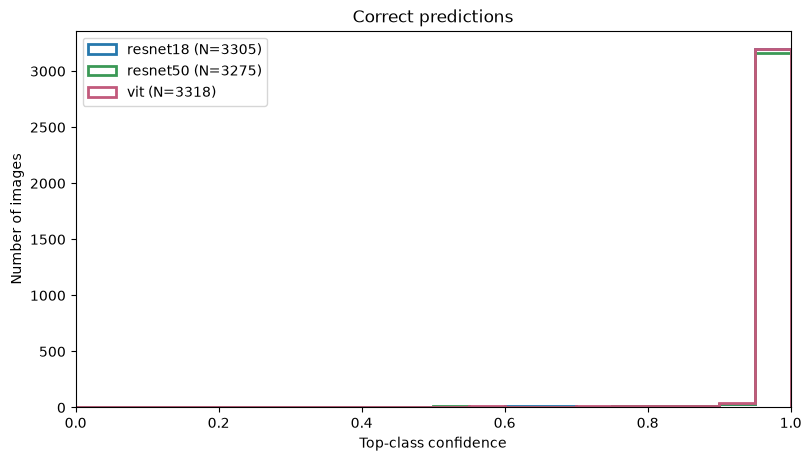

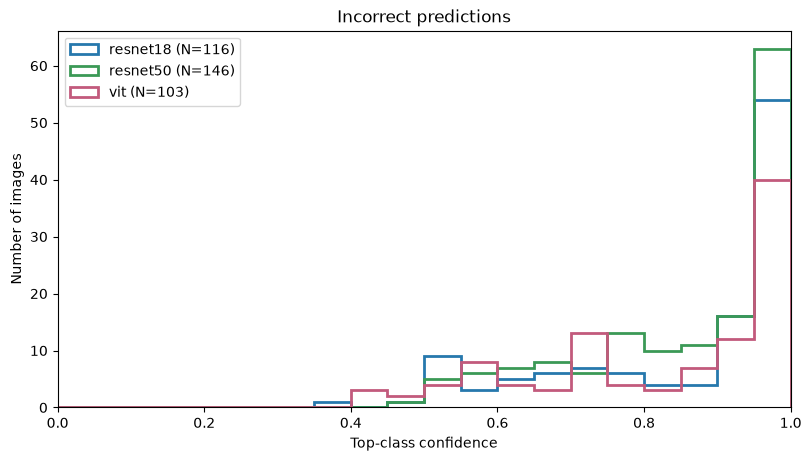

In [4]:
for is_correct, title in [(True, 'Correct predictions'), (False, 'Incorrect predictions')]:
    fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
    for m, color in enumerate(model_colors):
        mask = correct[m] == is_correct
        ax.hist(confidence[m, mask], bins=np.linspace(0, 1, 21), histtype='step',
                linewidth=2, color=color, label=f'{model_names[m]} (N={mask.sum()})')
    ax.set(title=title, xlabel='Top-class confidence', ylabel='Number of images', xlim=(0, 1))
    ax.legend()
    plt.show()

All three tested models appear overconfident: their mean confidence exceeds test accuracy, and some incorrect predictions remain highly confident. The plots do not tell us whether calibration-aware training was used. If these scores are displayed as trustworthy probabilities, they can mislead users, especially in high-risk applications. Calibration should therefore be checked and, if needed, fitted on separate validation data before the scores are shown to users.

## Confidence disagreement — each model's own maximum probability, not necessarily the same class

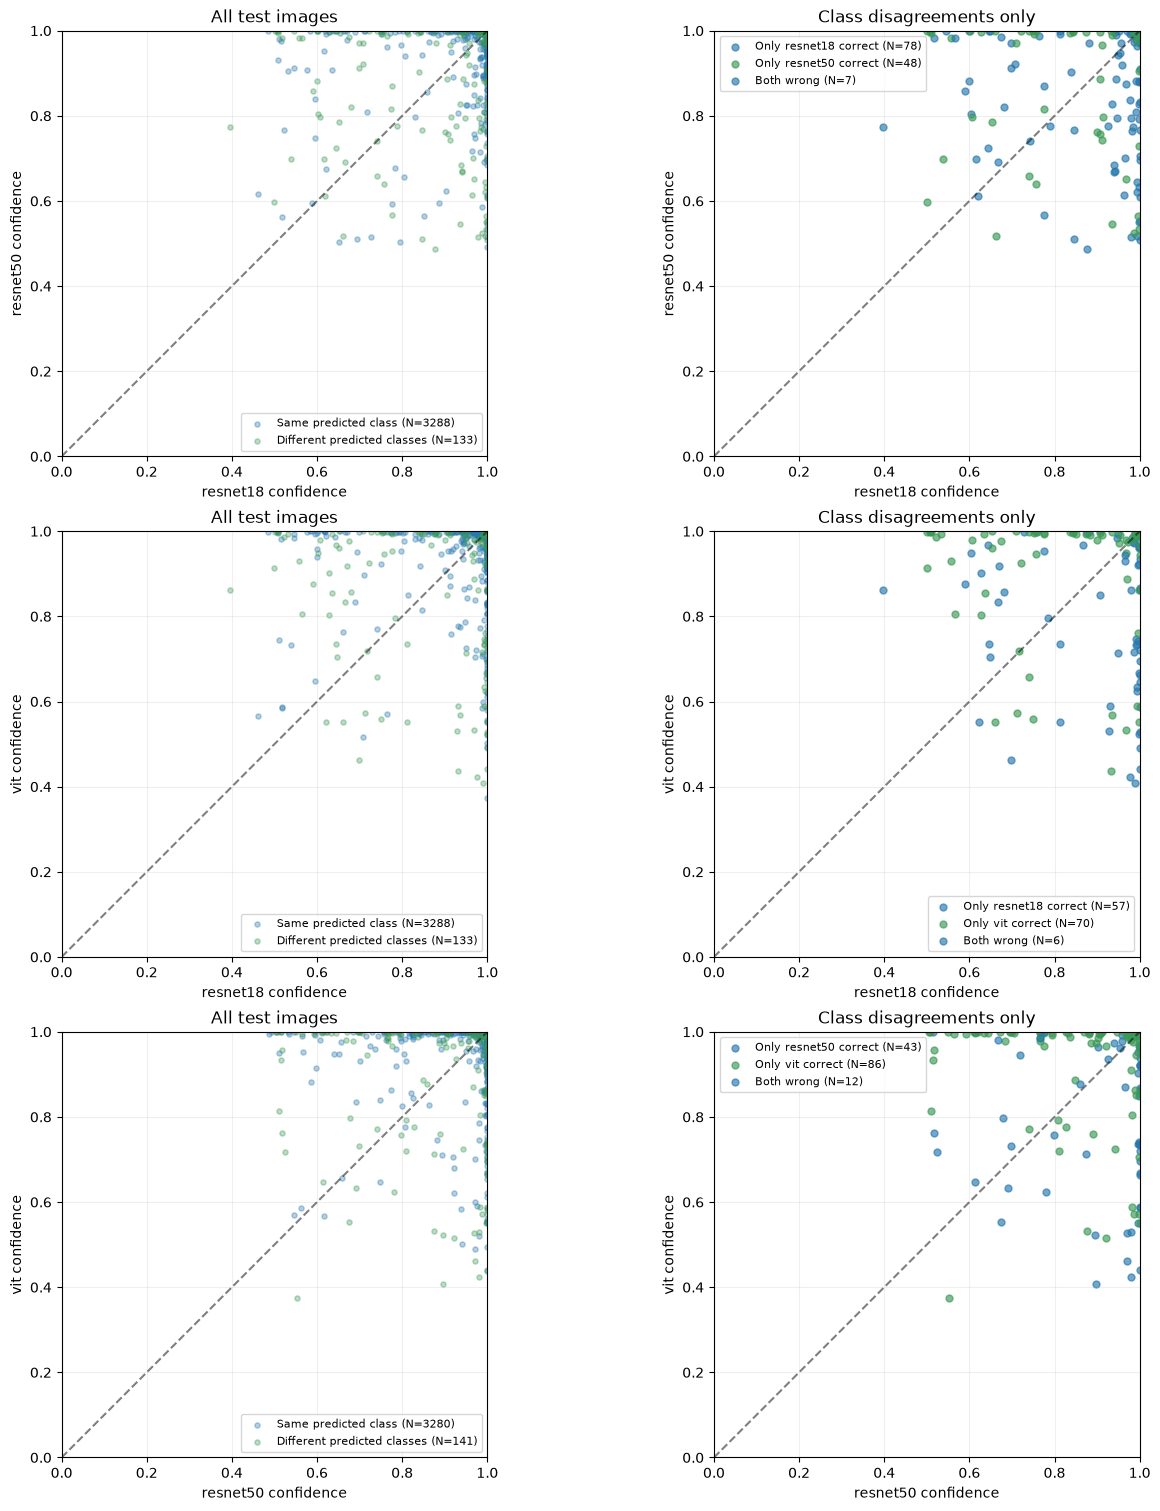

In [5]:
fig, axes = plt.subplots(len(pairs), 2, figsize=(13, 5 * len(pairs)), layout='constrained')
for row, (i, j) in enumerate(pairs):
    agree = predicted[i] == predicted[j]
    for mask, color, title in [(agree, 'C0', 'Same predicted class'), (~agree, 'C1', 'Different predicted classes')]:
        axes[row, 0].scatter(confidence[i, mask], confidence[j, mask], s=14, alpha=0.35,
                              color=color, label=f'{title} (N={mask.sum()})')
    groups = [(correct[i] & ~correct[j], 'C0', f'Only {model_names[i]} correct'),
              (~correct[i] & correct[j], 'C1', f'Only {model_names[j]} correct'),
              (~correct[i] & ~correct[j], 'C3', 'Both wrong')]
    for mask, color, title in groups:
        mask = mask & ~agree
        axes[row, 1].scatter(confidence[i, mask], confidence[j, mask], s=25, alpha=0.65,
                              color=color, label=f'{title} (N={mask.sum()})')
    for ax, title in zip(axes[row], ['All test images', 'Class disagreements only']):
        ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
        ax.set(title=title, xlabel=f'{model_names[i]} confidence', ylabel=f'{model_names[j]} confidence',
               xlim=(0, 1), ylim=(0, 1))
        ax.set_aspect('equal')
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
plt.show()


The models sometimes give different labels while both remain highly confident, so their scores do not automatically resolve disagreement. On disagreement cases, choosing the more confident model is correct in only about 59–65% of cases across the three pairs. This suggests that an ensemble needs a tested decision rule rather than simply trusting the largest score.

## Predictive entropy — normalized to [0, 1]; correct/error distributions and empirical error rate by entropy bin, with image counts

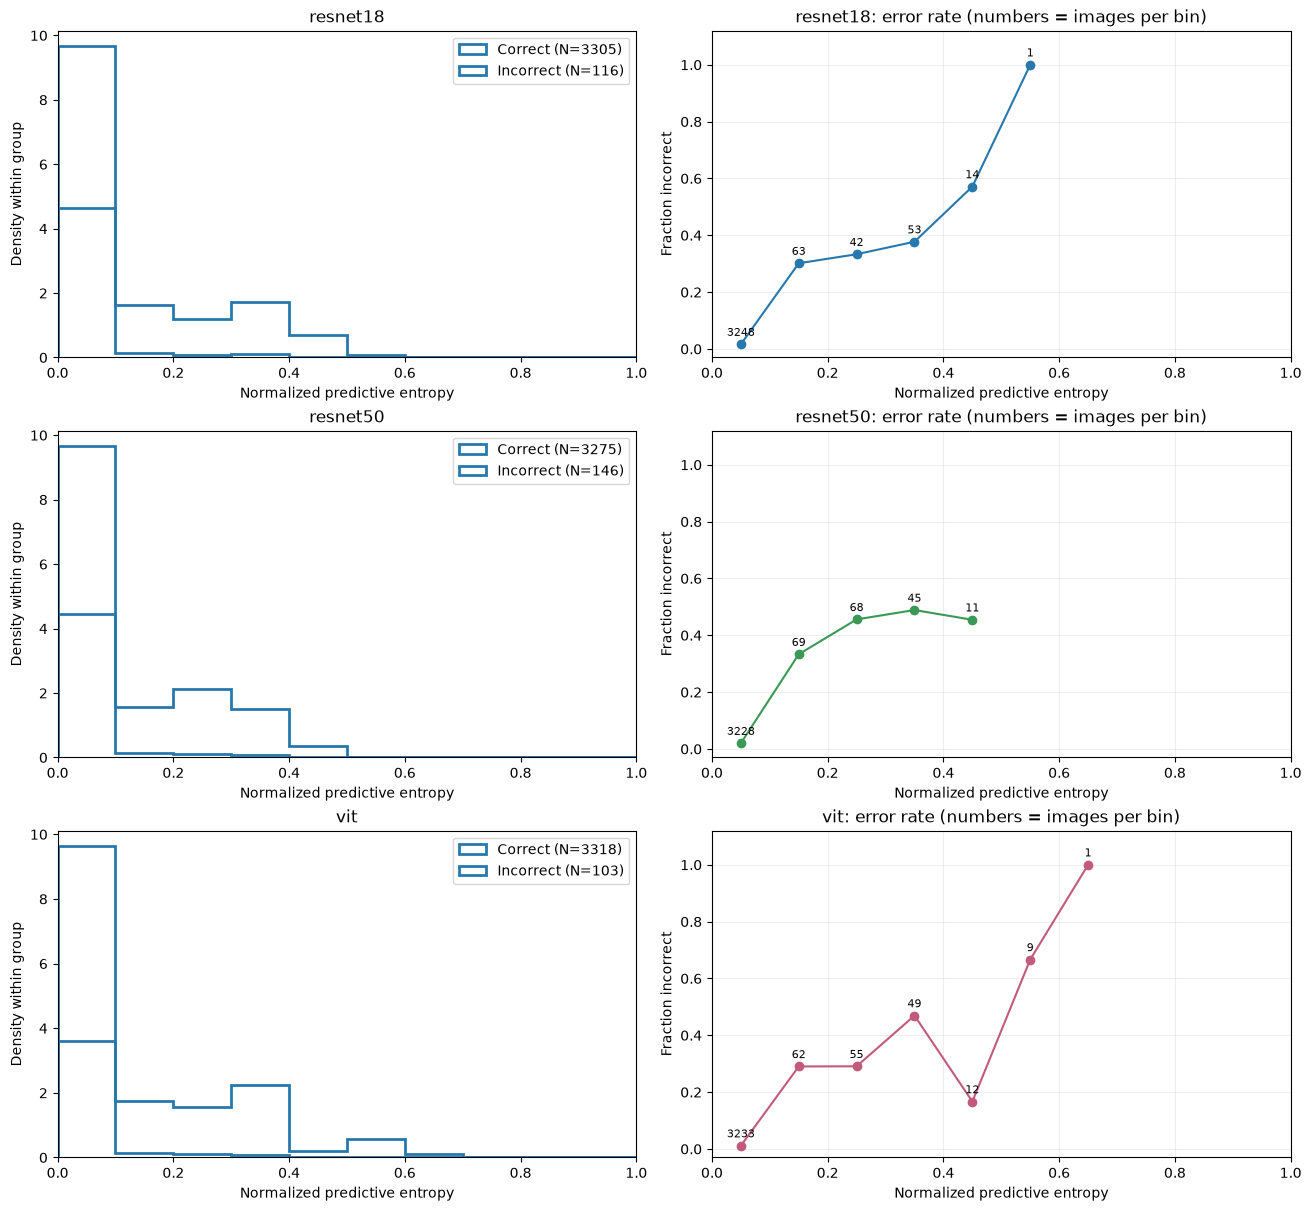

In [6]:
fig, axes = plt.subplots(len(model_names), 2, figsize=(13, 4 * len(model_names)), layout='constrained')
for m, name in enumerate(model_names):
    for mask, color, title in [(correct[m], 'C0', 'Correct'), (~correct[m], 'C3', 'Incorrect')]:
        if mask.any():
            axes[m, 0].hist(uncertainty[m, mask], bins=bins, density=True, histtype='step',
                            linewidth=2, color=color, label=f'{title} (N={mask.sum()})')
    axes[m, 0].set(title=name, xlabel='Normalized predictive entropy', ylabel='Density within group', xlim=(0, 1))
    axes[m, 0].legend()
    groups = bin_ids(uncertainty[m])
    counts = np.bincount(groups, minlength=n_bins)
    errors = np.bincount(groups, weights=~correct[m], minlength=n_bins)
    rates = np.divide(errors, counts, out=np.full(n_bins, np.nan), where=counts > 0)
    axes[m, 1].plot(centers, rates, 'o-', color=f'C{m}')
    for x, y, n in zip(centers, rates, counts):
        if n:
            axes[m, 1].annotate(str(n), (x, y), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=8)
    axes[m, 1].set(title=f'{name}: error rate (numbers = images per bin)',
                   xlabel='Normalized predictive entropy', ylabel='Fraction incorrect', xlim=(0, 1), ylim=(-0.03, 1.12))
    axes[m, 1].grid(alpha=0.2)
plt.show()

Errors have higher average entropy, but 47% of ResNet18 errors, 45% of ResNet50 errors and 36% of ViT errors still have normalized entropy below 0.1. Low entropy therefore means a concentrated prediction, not necessarily a correct one. The error-rate curves support using uncertainty as a warning signal, while the small counts in some bins limit how reliable any particular threshold would be.

## Confidence under transformations — all 3,421 test images; average noise repeats within each image; dashed lines show baseline

The absolute mean-confidence panel is omitted because the change panel contains the same curve shifted by its baseline. The remaining views distinguish score movement, confident errors and the spread of the full class distribution.

In [7]:
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved['model_names'], model_names)
    indices, stability_labels = saved['indices'], saved['labels']
    baseline = saved['baseline']
    levels = {key[7:]: saved[key] for key in saved.files if key.startswith('levels_')}
    transformed = {kind: saved[kind] for kind in levels}
np.testing.assert_array_equal(stability_labels, labels[indices])
np.testing.assert_allclose(baseline, probabilities[:, indices], atol=1e-9)
base_confidence = baseline.max(-1)
base_entropy = entropy(baseline)
base_high_wrong = (baseline.argmax(-1) != stability_labels) & (base_confidence >= threshold)
confidence_changes = {}
def plot_confidence_change(kind, p):
    conf = p.max(-1)
    high_wrong = (p.argmax(-1) != stability_labels) & (conf >= threshold)
    metrics = {
        'Change in top-class confidence': (conf - base_confidence[:, None, None, :]).mean(axis=2),
        f'Wrong with confidence ≥ {threshold:.0%} (all images)': high_wrong.mean(axis=2),
        'Normalized predictive entropy': entropy(p).mean(axis=2),
    }
    confidence_changes[kind] = metrics
    references = [np.zeros(len(model_names)), base_high_wrong.mean(-1), base_entropy.mean(-1)]
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), layout='constrained')
    reference = 1 if kind.endswith('_scale') or kind == 'brightness' else 0
    for ax, (title, values), original in zip(axes, metrics.items(), references):
        for m, name in enumerate(model_names):
            line, = ax.plot(levels[kind], values[m].mean(-1), 'o-', label=name)
            ax.axhline(original[m], color=line.get_color(), ls='--', alpha=0.4)
        ax.axvline(reference, color='gray', ls=':', alpha=0.5)
        ax.set(title=title, xlabel=kind)
        ax.grid(alpha=0.2)
    axes[0].legend()
    fig.suptitle(f'{kind} · N={len(stability_labels)} · confidence may increase even when predictions become wrong')
    plt.show()

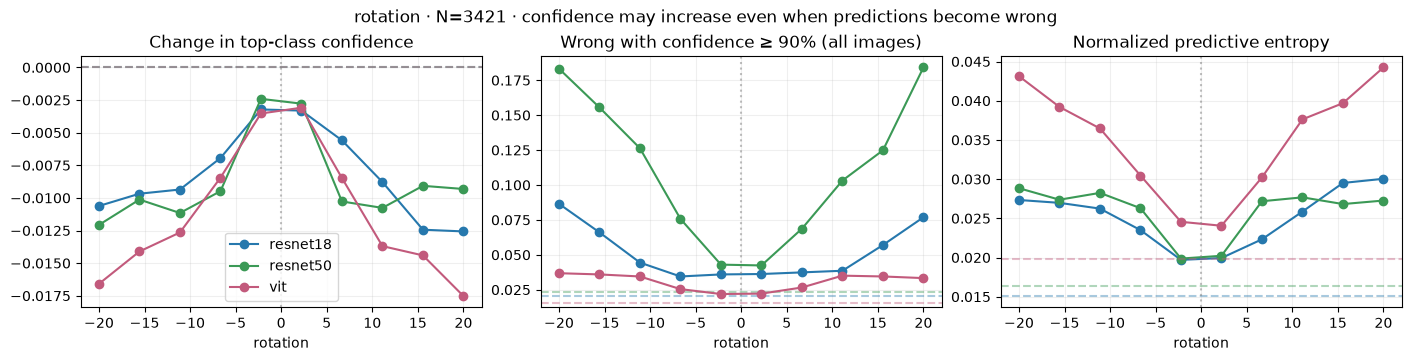

In [8]:
plot_confidence_change('rotation', transformed['rotation'])

Under rotation, ResNet50 loses 12.8 percentage points of original-class probability but only 0.9 points of maximum confidence. Its dominant class therefore changes much more than the concentration of its output distribution. The high-confidence-error fraction of 11.1% describes confidently wrong predictions across the full test population, including pre-existing errors.

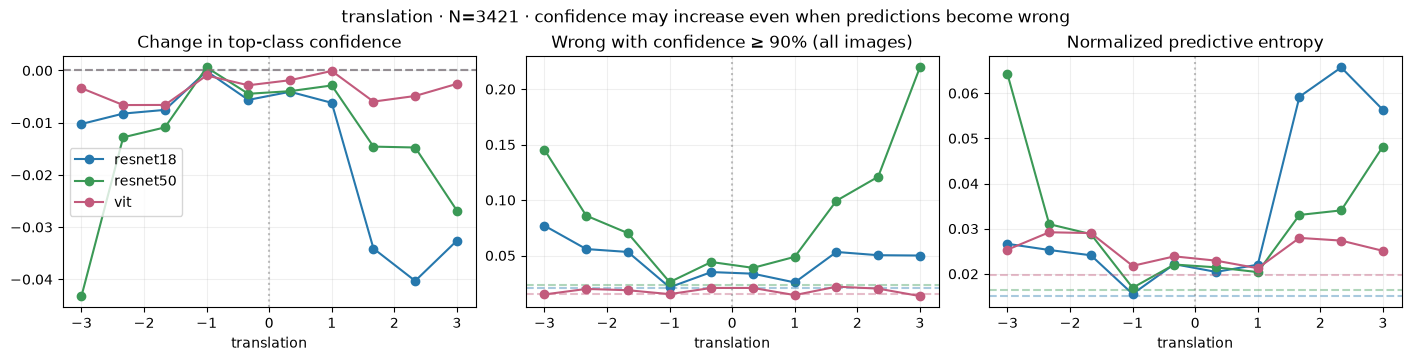

In [9]:
plot_confidence_change('translation', transformed['translation'])

Translation has a 9.0% high-confidence-error fraction for ResNet50 versus 1.8% for ViT. ResNet50 maximum confidence falls by only 1.3 percentage points despite its much larger loss of original-class support. The distinction is between uncertainty about one decision and replacement by another concentrated decision, not simply whether the score moves.

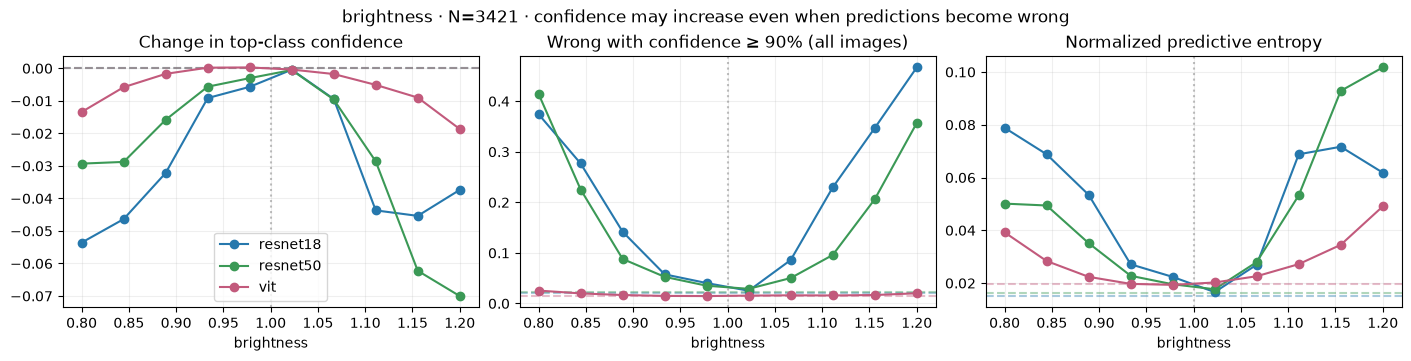

In [10]:
plot_confidence_change('brightness', transformed['brightness'])

Under brightness changes, high-confidence errors account for 20.5% of ResNet18 and 15.5% of ResNet50 image–level pairs, versus 1.8% for ViT. Both CNNs retain concentrated outputs while class accuracy falls to 71.3% and 77.4%. Brightness therefore changes which class receives confident support, rather than consistently producing an uncertainty signal before a wrong assignment.

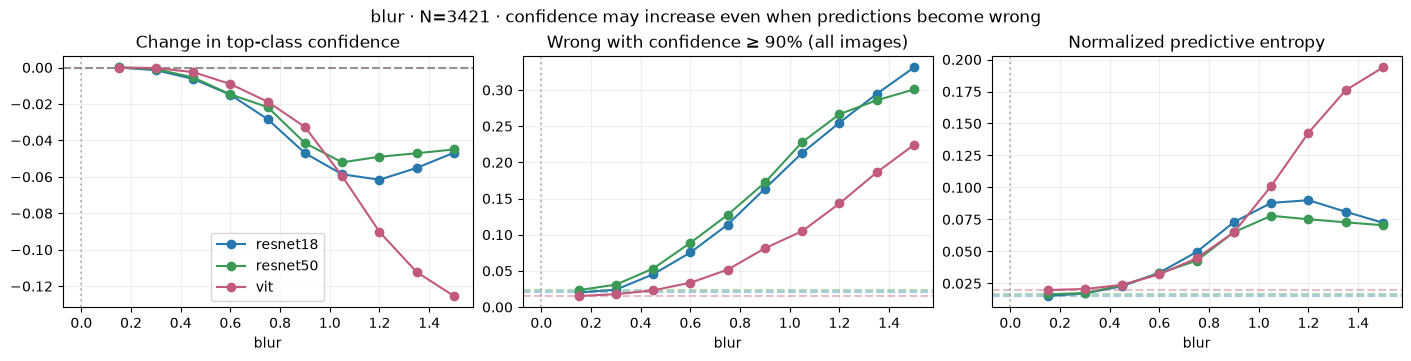

In [11]:
plot_confidence_change('blur', transformed['blur'])

Blur increases ViT’s normalized entropy to 0.082 on average, compared with 0.054 and 0.049 for the CNNs. Unlike its response to noise, ViT spreads probability across competing classes as spatial detail is removed. Its lower confident-error fraction of 8.8% does not eliminate failures, but distinguishes how the output distribution responds to this intervention.

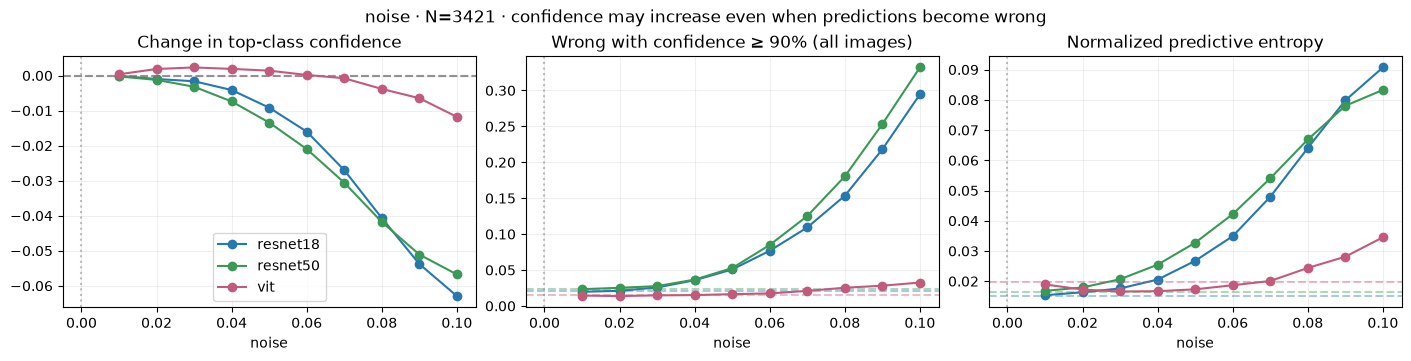

In [12]:
plot_confidence_change('noise', transformed['noise'])

ViT accuracy under noise averages 96.2%, close to its 97.0% baseline, and maximum confidence changes by only 0.2 percentage points. Here nearly unchanged confidence largely accompanies stable decisions, unlike the CNN brightness response. The high-confidence-error fraction of 2.0% still includes pre-existing errors, so it should not be interpreted entirely as newly induced noise failures.

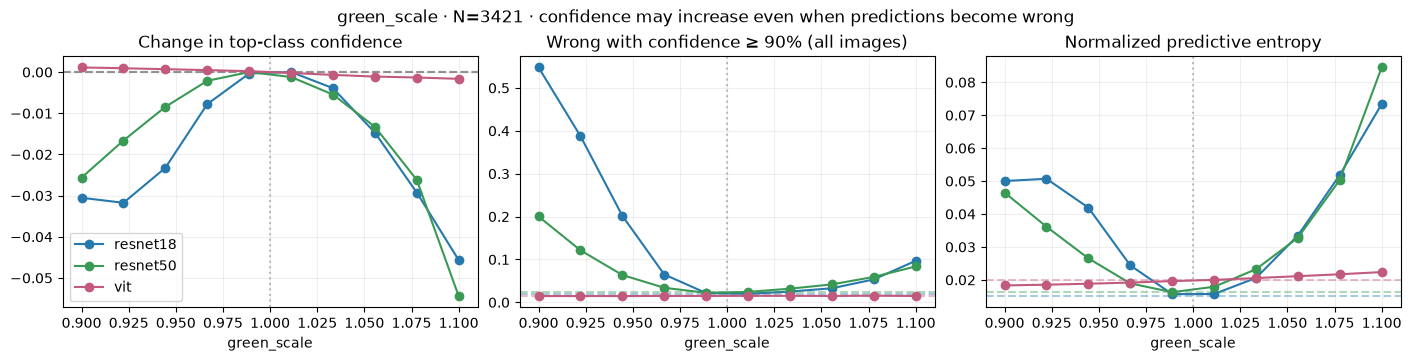

In [13]:
plot_confidence_change('green_scale', transformed['green_scale'])

ResNet18 produces high-confidence errors on 14.5% of green-scaling pairs despite a mean maximum-confidence loss of only 1.9 percentage points. Together with the strongly asymmetric accuracy curve, this shows a directional change in class assignment without proportional loss of certainty. The smaller ViT response constrains the finding to the tested checkpoints and preprocessing pipelines rather than a universal effect of green intensity.

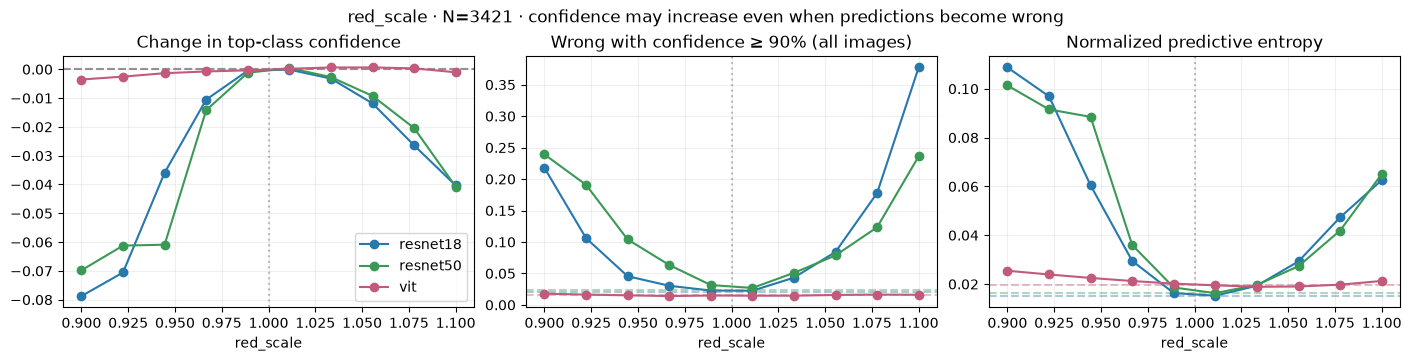

In [14]:
plot_confidence_change('red_scale', transformed['red_scale'])

Red scaling causes similar high-confidence-error fractions in the two CNNs: 11.3% and 11.5%. Original-class support falls by about 16 percentage points while maximum confidence falls by only 2.8 points. This is evidence of probability transferring between dominant classes, which a maximum-confidence summary alone would largely conceal.

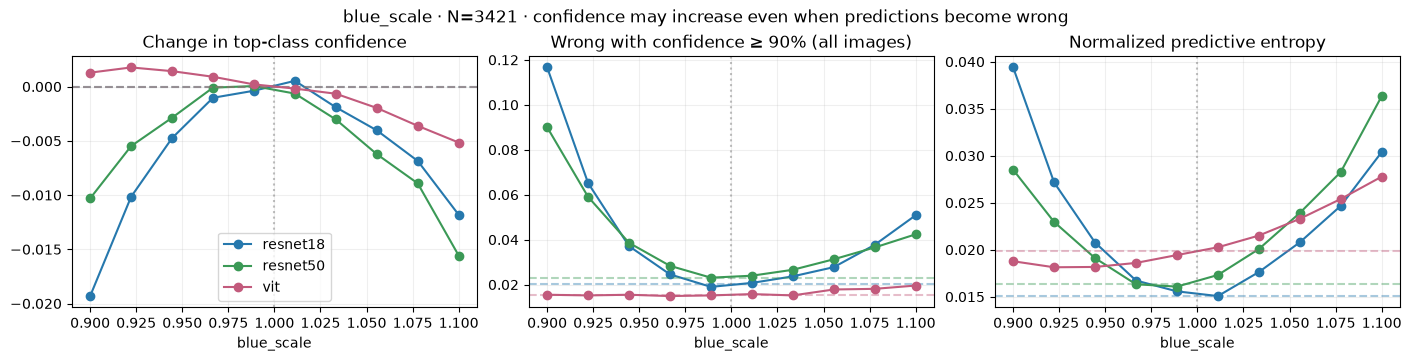

In [15]:
plot_confidence_change('blue_scale', transformed['blue_scale'])

Blue scaling produces smaller CNN high-confidence-error fractions, 4.2% and 4.0%, than red or green scaling over the same factor interval. The channel comparison therefore argues against a uniform response to every RGB gain change. The remaining individual failures still matter, but this figure’s main contribution is the contrast between channels rather than another general warning about confidence.

## Extract every high-confidence error — original RGB image, test index, labels, all probabilities, confidence and entropy; threshold editable above

In [16]:
high_confidence_wrong = {}
for m, name in enumerate(model_names):
    ids = np.flatnonzero(~correct[m] & (confidence[m] >= threshold))
    ids = ids[np.argsort(-confidence[m, ids], kind='stable')]
    high_confidence_wrong[name] = ids
    path = Path(f'predictions/high_confidence_wrong_{name}.npz')
    np.savez_compressed(path, images=images[ids], sample_index=ids, true_label=labels[ids],
                        predicted_label=predicted[m, ids], probabilities=probabilities[m, ids],
                        confidence=confidence[m, ids], normalized_entropy=uncertainty[m, ids],
                        class_names=class_names, model=name, split='test', threshold=threshold,
                        logits=np.load(f'predictions/{name}_test.npz')['logits'][ids])
    print(f'{name}: {len(ids)} high-confidence errors → {path}')


resnet18: 70 high-confidence errors → predictions\high_confidence_wrong_resnet18.npz
resnet50: 79 high-confidence errors → predictions\high_confidence_wrong_resnet50.npz
vit: 52 high-confidence errors → predictions\high_confidence_wrong_vit.npz


## High-confidence-error overlap — all three models and each model pair; model-relative percentages and Jaccard have different denominators

Errors shared by all three: 18 test IDs: [35, 340, 476, 496, 642, 839, 1413, 1462, 1629, 1750, 1762, 2384, 2434, 2649, 3015, 3126, 3329, 3373]
resnet18 / resnet50: shared 36, fractions 51.4% / 45.6%, Jaccard 31.9%
Same wrong class among shared errors: 97.2%
resnet18 / vit: shared 22, fractions 31.4% / 42.3%, Jaccard 22.0%
Same wrong class among shared errors: 95.5%
resnet50 / vit: shared 23, fractions 29.1% / 44.2%, Jaccard 21.3%
Same wrong class among shared errors: 95.7%


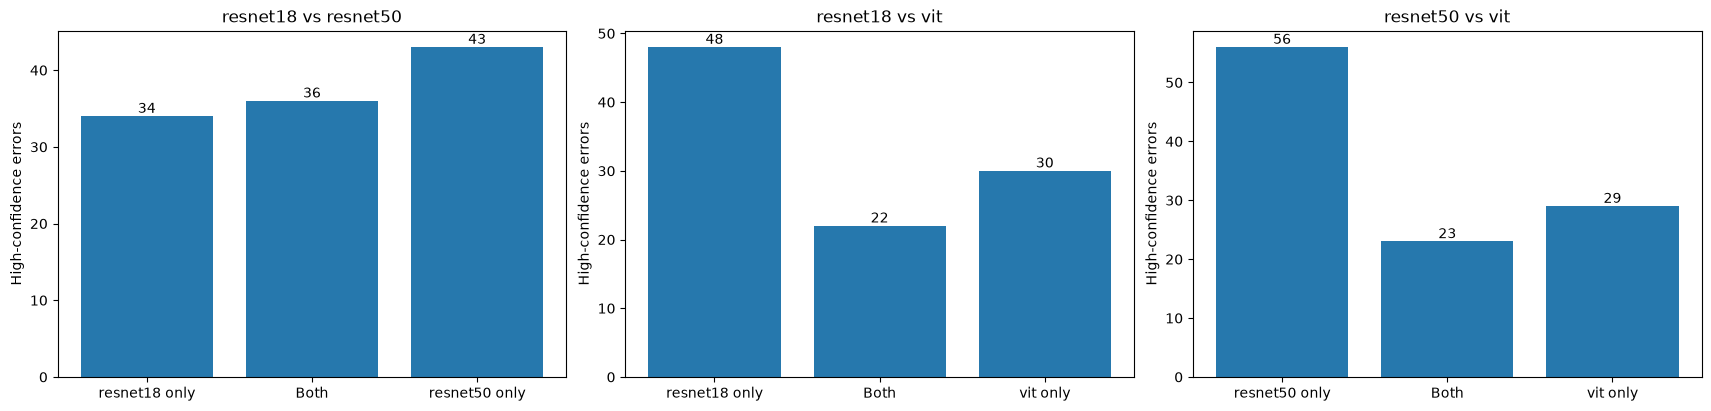

In [17]:
error_ids = [high_confidence_wrong[name] for name in model_names]
shared, union = error_ids[0].copy(), error_ids[0].copy()
for ids in error_ids[1:]:
    shared, union = np.intersect1d(shared, ids), np.union1d(union, ids)
print('Errors shared by all three:', len(shared), 'test IDs:', shared.tolist())
pair_overlap = np.zeros((len(model_names), len(model_names)), dtype=int)
pair_jaccard = np.full_like(pair_overlap, np.nan, dtype=float)
fig, axes = plt.subplots(1, len(pairs), figsize=(17, 4), layout='constrained')
for ax, (i, j) in zip(axes, pairs):
    common, combined = np.intersect1d(error_ids[i], error_ids[j]), np.union1d(error_ids[i], error_ids[j])
    pair_overlap[i, j] = pair_overlap[j, i] = len(common)
    pair_jaccard[i, j] = pair_jaccard[j, i] = len(common) / len(combined) if len(combined) else np.nan
    fractions = [len(common) / len(error_ids[m]) if len(error_ids[m]) else np.nan for m in (i, j)]
    print(f'{model_names[i]} / {model_names[j]}: shared {len(common)}, fractions {fractions[0]:.1%} / {fractions[1]:.1%}, Jaccard {pair_jaccard[i, j]:.1%}')
    if len(common):
        print(f'Same wrong class among shared errors: {(predicted[i, common] == predicted[j, common]).mean():.1%}')
    counts = [len(error_ids[i]) - len(common), len(common), len(error_ids[j]) - len(common)]
    ax.bar([f'{model_names[i]} only', 'Both', f'{model_names[j]} only'], counts)
    ax.bar_label(ax.containers[0])
    ax.set(ylabel='High-confidence errors', title=f'{model_names[i]} vs {model_names[j]}')
for m, ids in enumerate(error_ids):
    pair_overlap[m, m], pair_jaccard[m, m] = len(ids), 1 if len(ids) else np.nan
plt.show()


ResNet18 and ResNet50 share 36 high-confidence errors, compared with 22 and 23 for their respective pairs with ViT. Their Jaccard overlap is also higher, at 31.9% versus about 21–22%, so this is not just a comparison of raw error counts. The shared failures suggest that agreement can leave common blind spots, but the non-shared errors show that the models are not interchangeable.

## True class → wrong predicted class — counts and percentages within each model's high-confidence errors, not class-specific error rates

resnet18: immature granulocytes → monocyte: 13/70 (18.6%)
resnet18: immature granulocytes → neutrophil: 11/70 (15.7%)
resnet18: neutrophil → immature granulocytes: 9/70 (12.9%)
resnet18: immature granulocytes → lymphocyte: 6/70 (8.6%)
resnet18: monocyte → immature granulocytes: 5/70 (7.1%)
resnet50: monocyte → immature granulocytes: 12/79 (15.2%)
resnet50: neutrophil → immature granulocytes: 11/79 (13.9%)
resnet50: immature granulocytes → monocyte: 10/79 (12.7%)
resnet50: immature granulocytes → neutrophil: 10/79 (12.7%)
resnet50: basophil → immature granulocytes: 5/79 (6.3%)
vit: monocyte → immature granulocytes: 9/52 (17.3%)
vit: immature granulocytes → monocyte: 8/52 (15.4%)
vit: neutrophil → immature granulocytes: 8/52 (15.4%)
vit: basophil → immature granulocytes: 7/52 (13.5%)
vit: immature granulocytes → neutrophil: 6/52 (11.5%)


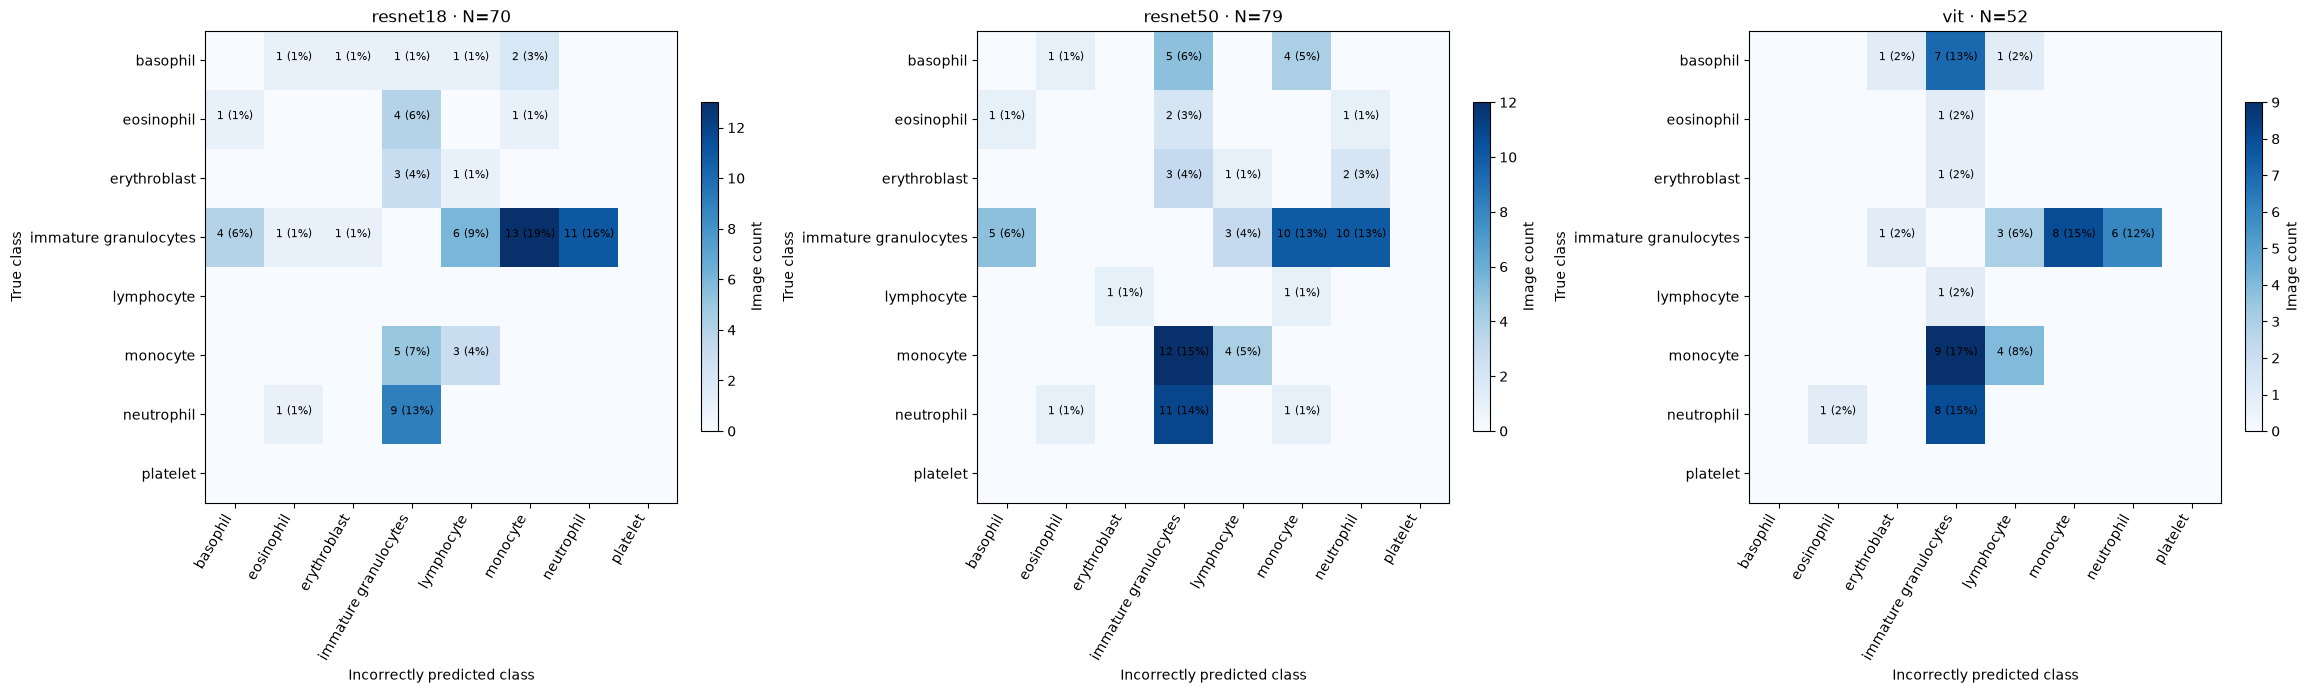

In [18]:
confusions, example_ids = [], []
fig, axes = plt.subplots(1, len(model_names), figsize=(23, 7), layout='constrained')
for m, (ax, ids) in enumerate(zip(axes, error_ids)):
    matrix = np.zeros((8, 8), dtype=int)
    np.add.at(matrix, (labels[ids], predicted[m, ids]), 1)
    confusions.append(matrix)
    im = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=max(matrix.max(), 1))
    ax.set(title=f'{model_names[m]} · N={len(ids)}', xlabel='Incorrectly predicted class', ylabel='True class',
           xticks=range(8), xticklabels=class_names, yticks=range(8), yticklabels=class_names)
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
    for c, d in zip(*np.nonzero(matrix)):
        ax.text(d, c, f'{matrix[c, d]} ({matrix[c, d] / len(ids):.0%})', ha='center', fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.6, label='Image count')
    pairs = np.dstack(np.unravel_index(np.argsort(-matrix.ravel(), kind='stable'), matrix.shape))[0]
    pairs = [(c, d) for c, d in pairs if matrix[c, d] > 0]
    for c, d in pairs[:5]:
        print(f'{model_names[m]}: {class_names[c]} → {class_names[d]}: {matrix[c, d]}/{len(ids)} ({matrix[c, d] / len(ids):.1%})')
    example_ids.append(np.array([ids[np.flatnonzero((labels[ids] == c) & (predicted[m, ids] == d))[0]] for c, d in pairs[:3]], dtype=int))
plt.show()

Immature granulocytes occur on either side of 58 of 70 ResNet18 error pairs, 61 of 79 ResNet50 pairs and 45 of 52 ViT pairs. The errors are therefore structured rather than spread evenly over all class combinations, but no single confusion explains them all. These plots show counts, not per-class error risk; the later class-rate heatmap checks whether the pattern is simply due to class frequency.

## Simple RGB features — boundary gradient energy is only a proxy for edge content, not cell location or segmentation

In [19]:
rgb = images.astype(float) / 255
luminance = rgb @ np.array([0.299, 0.587, 0.114])
maximum, minimum = rgb.max(-1), rgb.min(-1)
saturation = np.divide(maximum - minimum, maximum, out=np.zeros_like(maximum), where=maximum > 0)
gy, gx = np.gradient(luminance, axis=(1, 2))
energy = np.hypot(gx, gy)
border = np.ones((28, 28), dtype=bool)
border[4:-4, 4:-4] = False
boundary_energy = energy[:, border].sum(-1) / np.maximum(energy.sum((1, 2)), 1e-12)
features = np.column_stack((luminance.mean((1, 2)), saturation.mean((1, 2)),
                            rgb.mean((1, 2)), luminance.std((1, 2)), boundary_energy))
feature_names = ['Mean brightness', 'Mean saturation', 'Mean red', 'Mean green', 'Mean blue',
                 'Luminance contrast (std)', 'Boundary gradient fraction']
control_weights, feature_effects = [], []
for m, ids in enumerate(error_ids):
    weights = np.zeros(len(labels))
    for c in range(8):
        mask = correct[m] & (labels == c)
        if mask.any() and len(ids):
            weights[mask] = (labels[ids] == c).mean() / mask.sum()
    control_weights.append(weights)
    if not len(ids):
        feature_effects.append(np.full(len(feature_names), np.nan))
        continue
    mean = np.average(features, axis=0, weights=weights)
    std = np.sqrt(np.average((features - mean) ** 2, axis=0, weights=weights))
    effects = (features[ids].mean(0) - mean) / np.maximum(std, 1e-12)
    feature_effects.append(effects)

def plot_feature_comparison(m):
    ids = error_ids[m]
    weights, effects = control_weights[m], feature_effects[m]
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), layout='constrained')
    for j, ax in enumerate(axes.flat[:7]):
        edges = np.linspace(features[:, j].min(), features[:, j].max() + 1e-12, 16)
        ax.hist(features[:, j], bins=edges, weights=weights, histtype='step', linewidth=2, label='Correct, class-matched weights')
        ax.hist(features[ids, j], bins=edges, weights=np.full(len(ids), 1 / len(ids)),
                histtype='step', linewidth=2, label='High-confidence errors')
        ax.set(title=feature_names[j], ylabel='Fraction within group')
    axes[0, 0].legend(fontsize=7)
    axes[1, 3].barh(feature_names, effects)
    axes[1, 3].axvline(0, color='gray')
    axes[1, 3].set(title='Error minus correct mean', xlabel='Correct-control standard deviations')
    fig.suptitle(f'{model_names[m]} — correct controls weighted to the error group’s true-class proportions')
    plt.show()

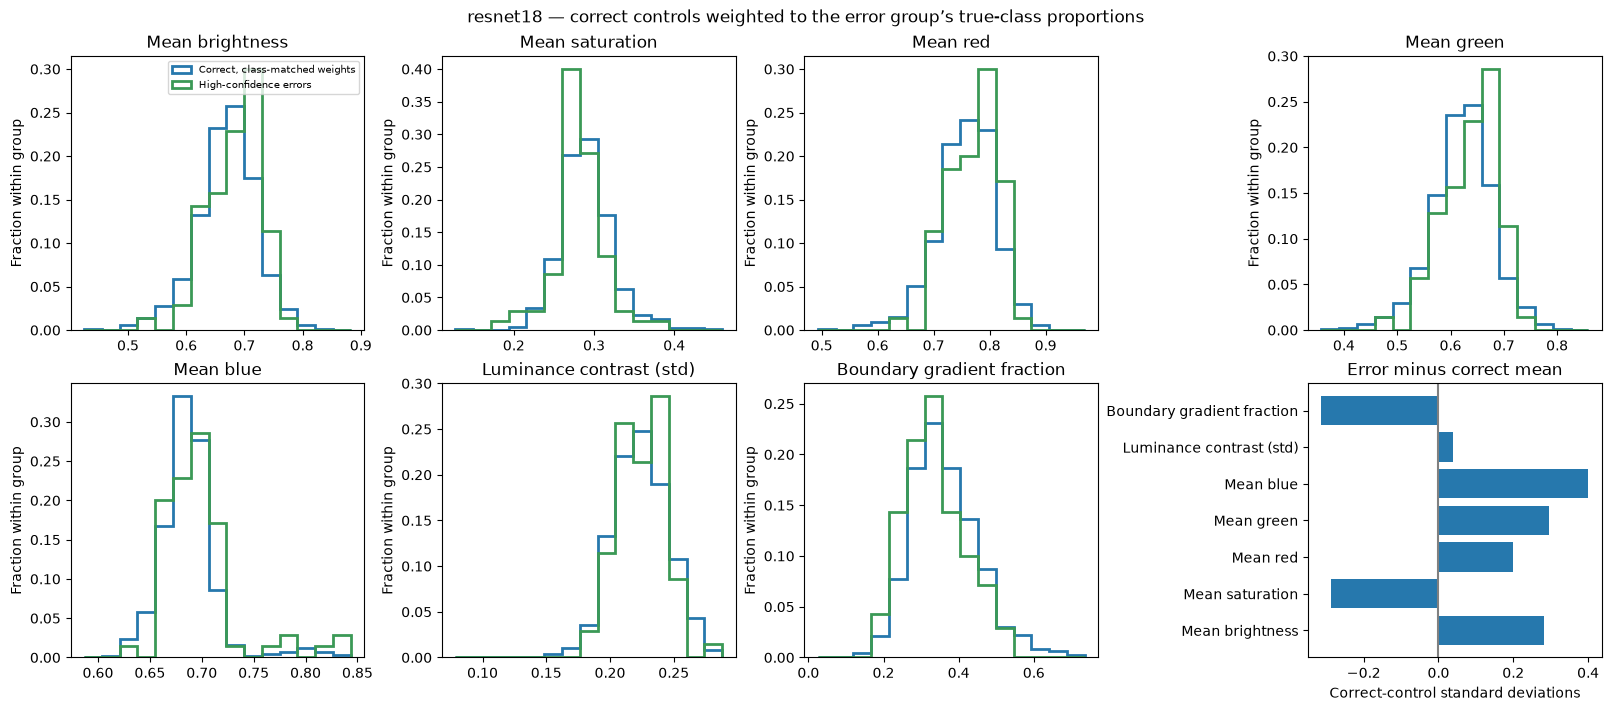

In [20]:
plot_feature_comparison(0)

ResNet18 high-confidence errors have somewhat higher blue values (+0.40 control SD) and lower saturation (−0.29 SD) than correctly classified, class-weighted controls. The overlapping distributions mean these properties cannot explain or detect every error. They suggest an appearance-related hypothesis worth testing, not a rule that brighter or less saturated cells must be misclassified.

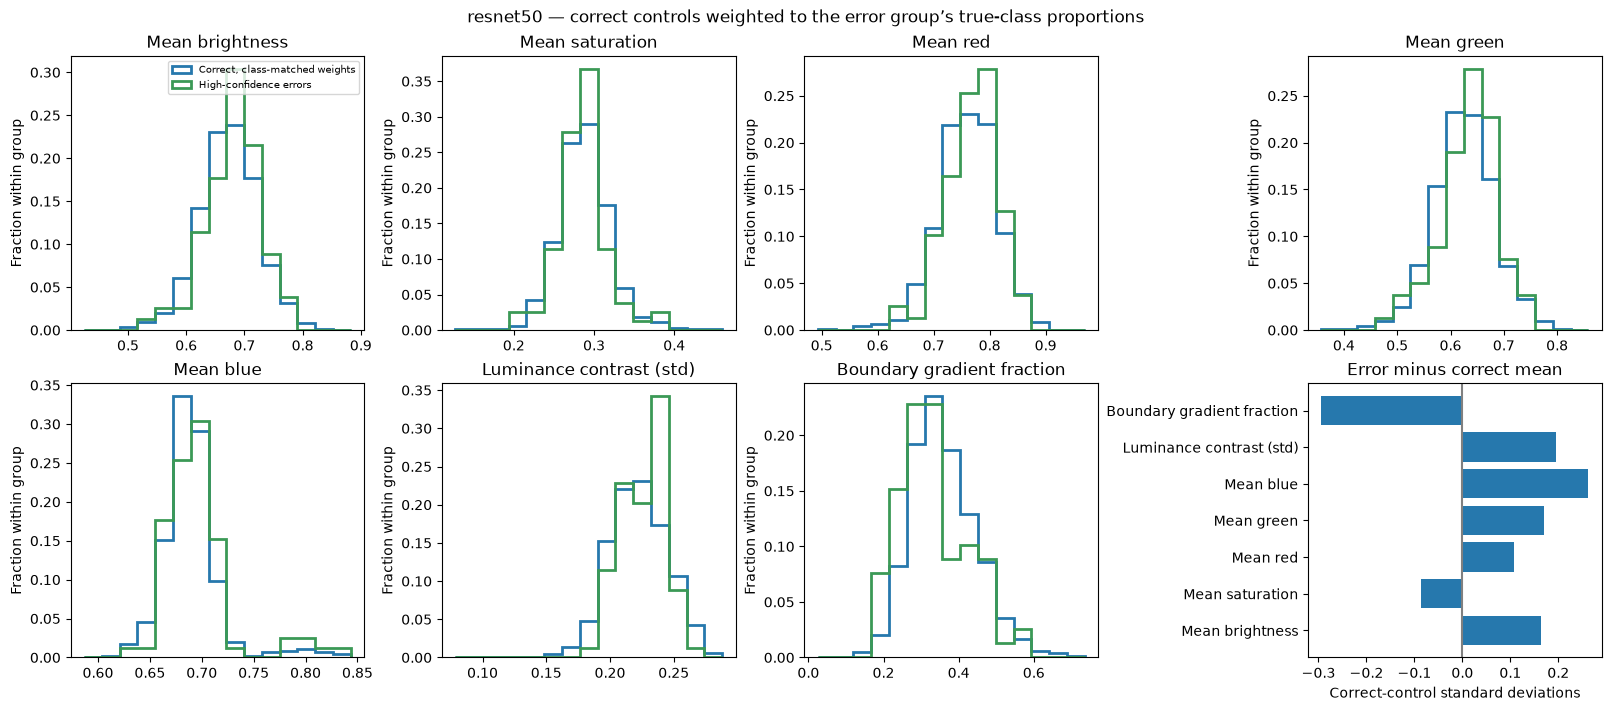

In [21]:
plot_feature_comparison(1)

ResNet50 errors show modest shifts, including higher blue values (+0.26 control SD) and lower boundary gradient fraction (−0.29 SD). There is no single feature that clearly separates the two groups. In particular, the boundary measure describes where image gradients occur, not whether an annotated cell lies near the border.

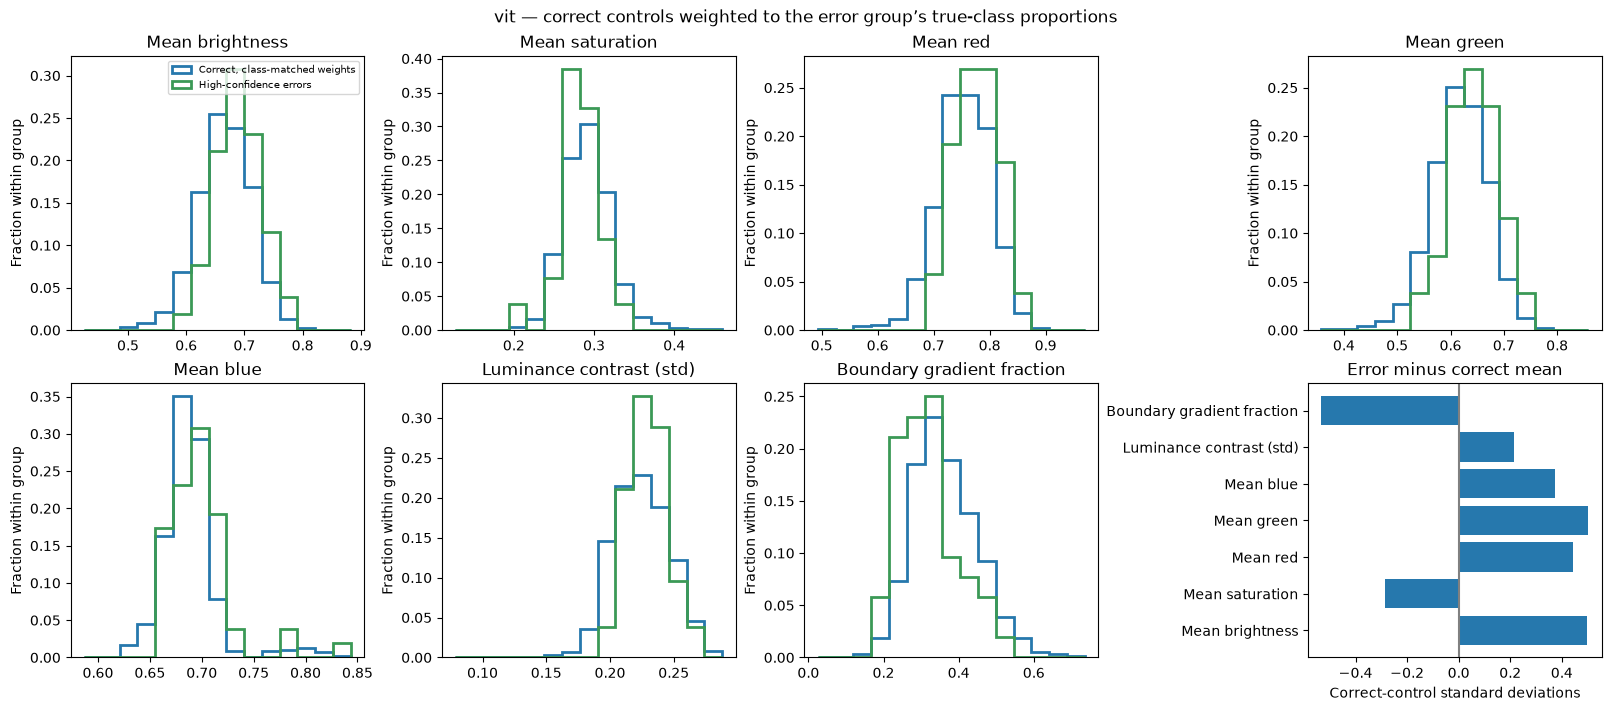

In [22]:
plot_feature_comparison(2)

ViT high-confidence errors are brighter (+0.50 control SD) and have less boundary gradient energy (−0.53 SD) than its class-weighted correct controls. These differences remain after matching the true-class proportions, but may still reflect several related appearance properties. They should guide controlled follow-up experiments rather than be interpreted as a discovered model mechanism.

## Nearest-image matches for the controlled galleries — raw RGB distance, restricted to the relevant true or predicted class

In [23]:
flat = rgb.reshape(len(images), -1).astype(np.float32)
squared = np.square(flat).sum(-1)
neighbor_ids, neighbor_rmse = [], []
for m, ids in enumerate(error_ids):
    distances = np.maximum(squared[:, None] + squared[ids][None, :] - 2 * flat @ flat[ids].T, 0) / flat.shape[1]
    matches, rmses = [], []
    for target in [labels[ids], predicted[m, ids]]:
        allowed = correct[m, :, None] & (confidence[m, :, None] >= threshold) & (labels[:, None] == target[None, :])
        assert allowed.any(axis=0).all(), 'No correct comparison image in a requested class'
        nearest = np.where(allowed, distances, np.inf).argmin(axis=0)
        matches.append(nearest)
        rmses.append(np.sqrt(distances[nearest, np.arange(len(ids))]))
    neighbor_ids.append(np.stack(matches))
    neighbor_rmse.append(np.stack(rmses))


## Load models for interventions — no training; saturation and occlusion act on original 28 × 28 RGB images

In [24]:
import torch
from PIL import Image, ImageEnhance
from transformers import ViTForImageClassification, ViTImageProcessor
from torchvision.models import resnet18
from models.resnet18.models import ResNet50

torch.manual_seed(42)
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
batch_size = 32
models = [resnet18(weights=None, num_classes=8), ResNet50(in_channels=3, num_classes=8)]
checkpoints = ['weights_bloodmnist/resnet18_224_1.pth', 'weights_bloodmnist/resnet50_28_1.pth', 'models/vit']
for model, path in zip(models, checkpoints):
    model.load_state_dict(torch.load(path, map_location='cpu', weights_only=True)['net'])
models.append(ViTForImageClassification.from_pretrained('models/vit', local_files_only=True))
models = [model.to(device).eval() for model in models]
processor = ViTImageProcessor.from_pretrained('models/vit', local_files_only=True)

@torch.inference_mode()
def predict(m, images):
    probabilities, scores = [], []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]
        if model_names[m] != 'vit':
            x = torch.from_numpy(batch.copy()).permute(0, 3, 1, 2).to(device).float()
            if model_names[m] == 'resnet18':
                x = torch.nn.functional.interpolate(x, size=(224, 224), mode='nearest')
            logits = models[m]((x / 255 - 0.5) / 0.5)
        else:
            inputs = processor(images=list(batch), return_tensors='pt').to(device)
            logits = models[m](**inputs).logits
        probabilities.append(logits.softmax(-1).cpu().numpy())
        scores.append(logits.cpu().numpy())
    return np.concatenate(probabilities), np.concatenate(scores)

def intervention_predict(m, batch_images):
    return predict(m, batch_images)[0]

for m, ids in enumerate(error_ids):
    if len(ids):
        np.testing.assert_allclose(intervention_predict(m, images[ids]), probabilities[m, ids], atol=1e-5, rtol=1e-4)


## Saturation intervention — HC errors versus nearest same-class correct ≥90%-confident controls; repeated controls are not independent samples

In [25]:
saturation_levels = np.linspace(0.5, 1.5, 11)
saturation_results, saturation_ids = [], []
saturation_cache = {}
if Path('predictions/high_confidence_error_analysis.npz').exists():
    with np.load('predictions/high_confidence_error_analysis.npz', allow_pickle=False) as saved:
        if np.array_equal(saved['baseline_probabilities'], probabilities) and np.array_equal(saved['saturation_levels'], saturation_levels):
            for m, name in enumerate(model_names):
                selected = np.stack((error_ids[m], neighbor_ids[m][0]))
                if np.array_equal(saved[f'{name}_saturation_ids'], selected):
                    saturation_cache[m] = saved[f'{name}_saturation_probabilities']
for m, ids in enumerate(error_ids):
    selected = np.stack((ids, neighbor_ids[m][0]))
    saturation_ids.append(selected)
    if not len(ids):
        saturation_results.append(np.empty((2, 11, 0, 8)))
        continue
    if m in saturation_cache:
        saturation_results.append(saturation_cache[m])
        continue
    inputs = images[selected.ravel()]
    values = []
    for level in saturation_levels:
        changed = np.stack([np.asarray(ImageEnhance.Color(Image.fromarray(image)).enhance(float(level))) for image in inputs])
        values.append(intervention_predict(m, changed).reshape(2, len(ids), 8))
    p = np.stack(values, axis=1)
    saturation_results.append(p)
    np.testing.assert_allclose(p[:, 5], probabilities[m, selected], atol=1e-5, rtol=1e-4)


def plot_saturation(m):
    ids, selected, p = error_ids[m], saturation_ids[m], saturation_results[m]
    original = probabilities[m, selected].argmax(-1)
    retained = np.take_along_axis(p, original[:, None, :, None], axis=-1)[..., 0]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
    for role, name in enumerate(['HC errors', 'Matched correct controls']):
        axes[0, 0].plot(saturation_levels, retained[role].mean(-1), 'o-', label=name)
        axes[0, 1].plot(saturation_levels, (p[role].argmax(-1) == labels[selected[role]]).mean(-1), 'o-', label=name)
        distribution = np.stack([(p[role].argmax(-1) == c).mean(-1) for c in range(8)])
        im = axes[1, role].imshow(distribution, vmin=0, vmax=1, cmap='Blues', aspect='auto')
        axes[1, role].set(title=name, yticks=range(8), yticklabels=class_names,
                          xticks=[0, 5, 10], xticklabels=['0.5', '1.0', '1.5'], xlabel='Saturation factor')
    axes[0, 0].set(title='Support for each original decision', ylabel='Mean probability')
    axes[0, 1].set(title='Fraction selecting the recorded true class', ylabel='Fraction')
    for ax in axes[0]:
        ax.axvline(1, color='gray', ls='--')
        ax.set_xlabel('Saturation factor')
        ax.legend(fontsize=8)
    fig.colorbar(im, ax=axes[1], label='Fraction assigned to each class')
    fig.suptitle(f'{model_names[m]} · same-class paired cohorts · N={len(ids)}')
    plt.show()


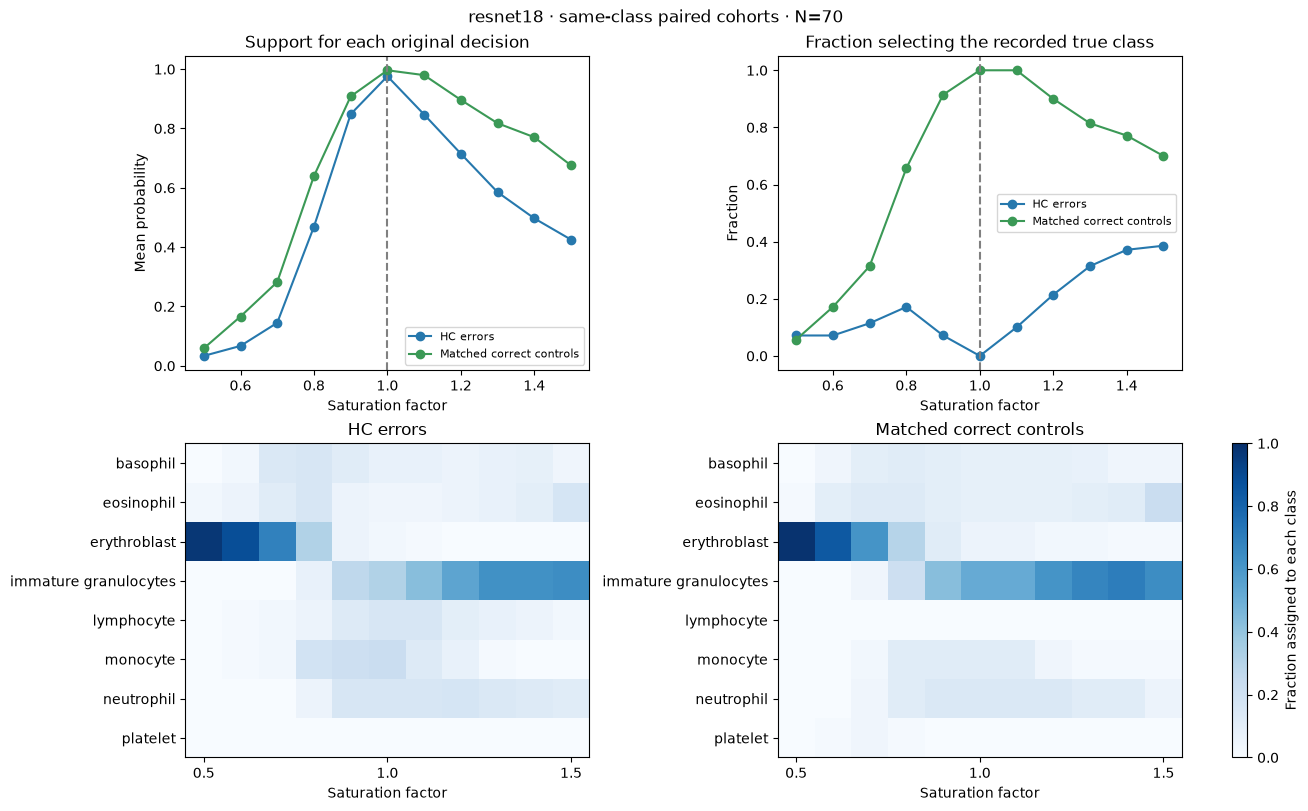

In [26]:
plot_saturation(0)

At saturation ×0.5, ResNet18 assigns erythroblast to 68/70 error images and 69/70 class-matched correct controls. The common destination across two different starting states identifies a class-attractor response, not a selective property of initially wrong images. It motivates checking which class-associated appearance cues are lost under desaturation; the resulting true-label matches alone would obscure this collapse.

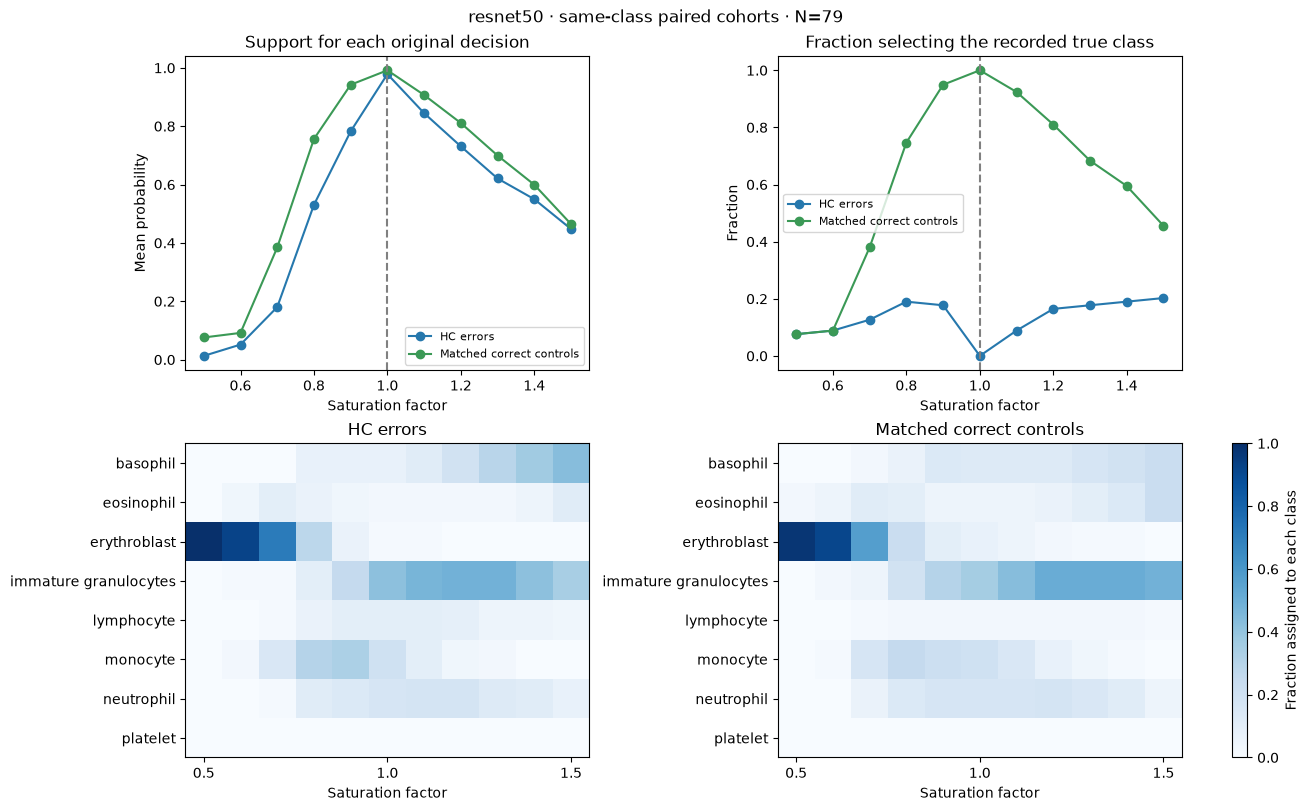

In [27]:
plot_saturation(1)

At saturation ×0.5, ResNet50 assigns all 79 error images and 77/79 matched correct controls to erythroblast. Because the cohorts have the same true-class composition, this convergence cannot be explained by one cohort simply containing more erythroblasts. The result supports a strong color-dependent class assignment in this checkpoint under the intervention, rather than identifying saturation as a general remedy.

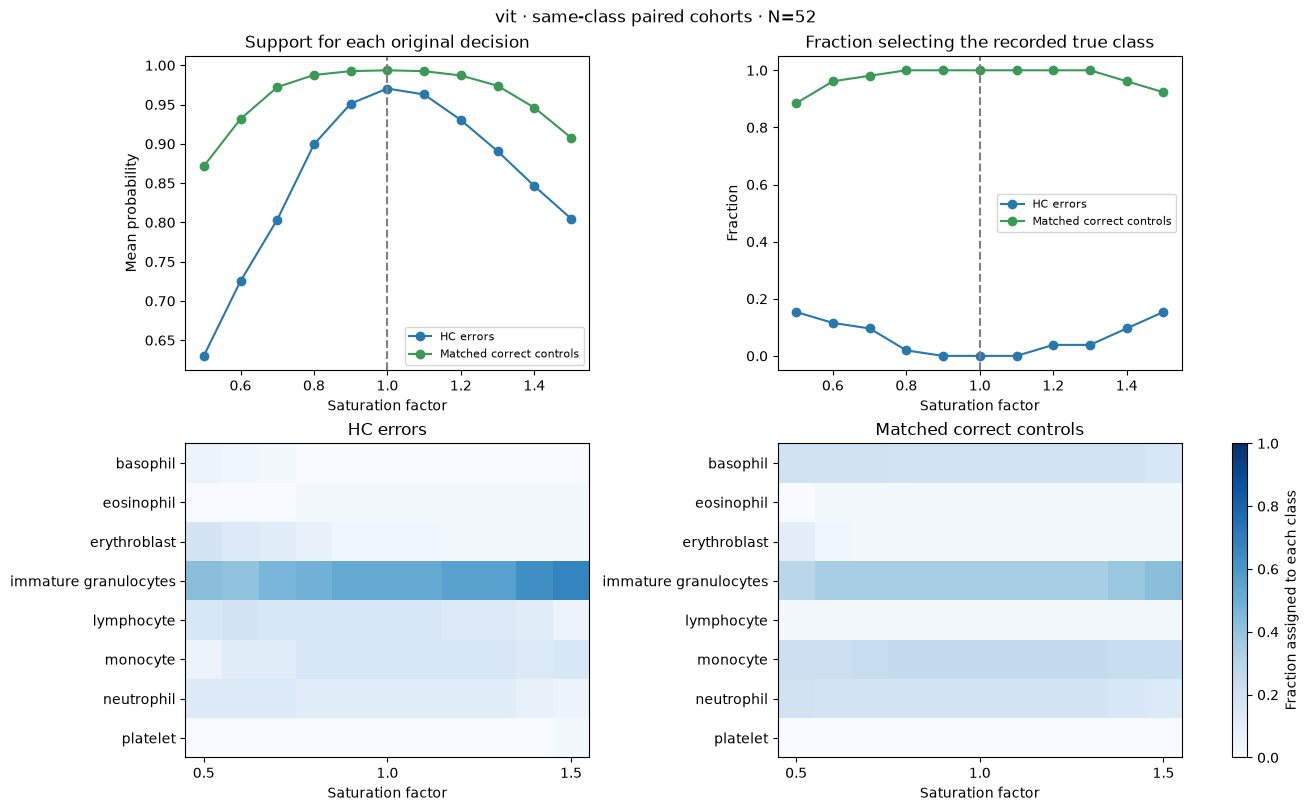

In [28]:
plot_saturation(2)

ViT does not show the same near-complete erythroblast collapse under desaturation. At ×0.5, its original-decision probability drops by 0.340 for the error cohort versus 0.122 for matched correct controls, indicating a more error-specific response in these samples. This difference is a hypothesis about conditional appearance sensitivity; it does not identify the internal feature responsible for the original error.

## Model-wide occlusion — all 3,421 test images, all classes and confidence levels

Each model receives the same 49 gray 4×4 patches before its usual preprocessing. The original predicted class is held fixed when measuring probability loss. Accuracy change uses the complete test population; the high-confidence-error analysis below is a separate conditional view.

In [29]:
import hashlib
from numpy.lib.format import open_memmap

patch_size = 4
positions = np.array([(y, x) for y in range(0, 28, patch_size) for x in range(0, 28, patch_size)])
files = [*checkpoints[:2], 'models/vit/model.safetensors', 'models/vit/config.json', 'models/vit/preprocessor_config.json']
weight_hashes = [hashlib.sha256(Path(path).read_bytes()).hexdigest() for path in files]
signature = hashlib.sha256(images.tobytes() + labels.tobytes() + probabilities.tobytes() + positions.tobytes()
                           + str(weight_hashes).encode() + b'gray128_resnet18-nearest224_resnet50-28_vit-local_v1').hexdigest()
population_path = Path('predictions/occlusion_test.npz')
if not population_path.exists():
    cache = Path('outputs/occlusion_test_v1')
    cache.mkdir(parents=True, exist_ok=True)
    lock = cache / 'signature.txt'
    assert not lock.exists() or lock.read_text() == signature, 'Inputs changed: use a new cache directory.'
    lock.write_text(signature)
    arrays = []
    for filename, shape, dtype in [('probabilities.npy', (3, 49, len(images), 8), 'float32'),
                                    ('logits.npy', (3, 49, len(images), 8), 'float32'), ('done.npy', (3, 49), 'bool')]:
        path = cache / filename
        fresh = not path.exists()
        array = open_memmap(path, mode='w+' if fresh else 'r+', dtype=dtype, shape=shape)
        if fresh and dtype == 'bool':
            array[:] = False
            array.flush()
        arrays.append(array)
    population_p, population_logits, done = arrays
    for m, name in enumerate(model_names):
        np.testing.assert_allclose(predict(m, images[:64])[0], probabilities[m, :64], atol=1e-5, rtol=1e-4)
        for j, (y, x) in enumerate(positions):
            if done[m, j]:
                continue
            changed = images.copy()
            changed[:, y:y + patch_size, x:x + patch_size] = 128
            population_p[m, j], population_logits[m, j] = predict(m, changed)
            population_p.flush()
            population_logits.flush()
            done[m, j] = True
            done.flush()
        print(f'{name}: all {len(images)} test images × 49 patch positions completed')
    np.savez_compressed(population_path, probabilities=population_p, logits=population_logits,
                        sample_index=np.arange(len(images)), labels=labels, baseline_probabilities=probabilities,
                        model_names=model_names, checkpoints=checkpoints, weight_hashes=weight_hashes,
                        class_names=class_names, positions=positions, patch_size=patch_size, fill_rgb=[128]*3,
                        signature=signature, split='test', axes=['model', 'patch', 'image', 'class'])
with np.load(population_path, allow_pickle=False) as saved:
    assert str(saved['signature']) == signature, 'Cached experiment does not match current inputs.'
    population_p = saved['probabilities']
print(f'Model-wide occlusion: {len(images)} shared test images per model; no confidence filtering')


Model-wide occlusion: 3421 shared test images per model; no confidence filtering


In [30]:
population_prediction = population_p.argmax(-1)
population_original = np.take_along_axis(population_p, predicted[:, None, :, None], axis=-1)[..., 0]
population_drop = (confidence[:, None] - population_original).transpose(0, 2, 1).reshape(3, len(labels), 7, 7)
population_correct = population_prediction == labels
population_before = predicted == labels
population_maps = {
    'Original-decision probability drop': population_drop.mean(1),
    'Label flip fraction': (population_prediction != predicted[:, None]).mean(-1).reshape(3, 7, 7),
    'Accuracy change (percentage points)': 100 * (population_correct.mean(-1) - population_before.mean(-1)[:, None]).reshape(3, 7, 7),
}
population_class_drop = np.stack([population_drop[:, labels == c].mean(1) for c in range(8)], axis=1)
population_group_difference = np.full((3, 8, 7, 7), np.nan)
population_group_counts = np.zeros((3, 8, 2), dtype=int)
for m in range(3):
    for c in range(8):
        right = (labels == c) & population_before[m]
        wrong = (labels == c) & ~population_before[m]
        population_group_counts[m, c] = [wrong.sum(), right.sum()]
        if wrong.any() and right.any():
            population_group_difference[m, c] = population_drop[m, wrong].mean(0) - population_drop[m, right].mean(0)

def plot_population_overview():
    fig, axes = plt.subplots(3, 3, figsize=(13, 11), layout='constrained')
    for col, (title, maps) in enumerate(population_maps.items()):
        signed = col != 1
        scale = max(np.abs(maps).max(), 0.01)
        for m, ax in enumerate(axes[:, col]):
            im = ax.imshow(maps[m], cmap='RdBu_r' if signed else 'viridis', vmin=-scale if signed else 0, vmax=scale)
            ax.set(title=f'{model_names[m]} · {title}', xticks=[], yticks=[])
        fig.colorbar(im, ax=axes[:, col], shrink=0.7)
    fig.suptitle('Model-wide occlusion · all 3,421 test images · same 49 gray patches for every model')
    plt.show()

def plot_population_classes(difference=False):
    maps = population_group_difference if difference else population_class_drop
    limit = max(np.nanmax(np.abs(maps)), 0.01)
    fig, axes = plt.subplots(3, 8, figsize=(23, 10), layout='constrained')
    for m in range(3):
        for c, ax in enumerate(axes[m]):
            im = ax.imshow(maps[m, c], cmap='RdBu_r', vmin=-limit, vmax=limit)
            count = f'wrong/right: {population_group_counts[m, c, 0]}/{population_group_counts[m, c, 1]}' if difference else f'N={(labels == c).sum()}'
            ax.set(title=f'{class_names[c]} · {count}', xticks=[], yticks=[])
            if difference and not np.isfinite(maps[m, c]).any():
                ax.text(0.5, 0.5, 'No initial errors', ha='center', transform=ax.transAxes)
        axes[m, 0].set_ylabel(model_names[m])
    fig.colorbar(im, ax=axes, shrink=0.7, label='Wrong minus correct decision-support drop' if difference else 'Mean original-decision probability drop')
    fig.suptitle('Within-class comparison: initially wrong minus initially correct' if difference else 'All test images, grouped by true class')
    plt.show()


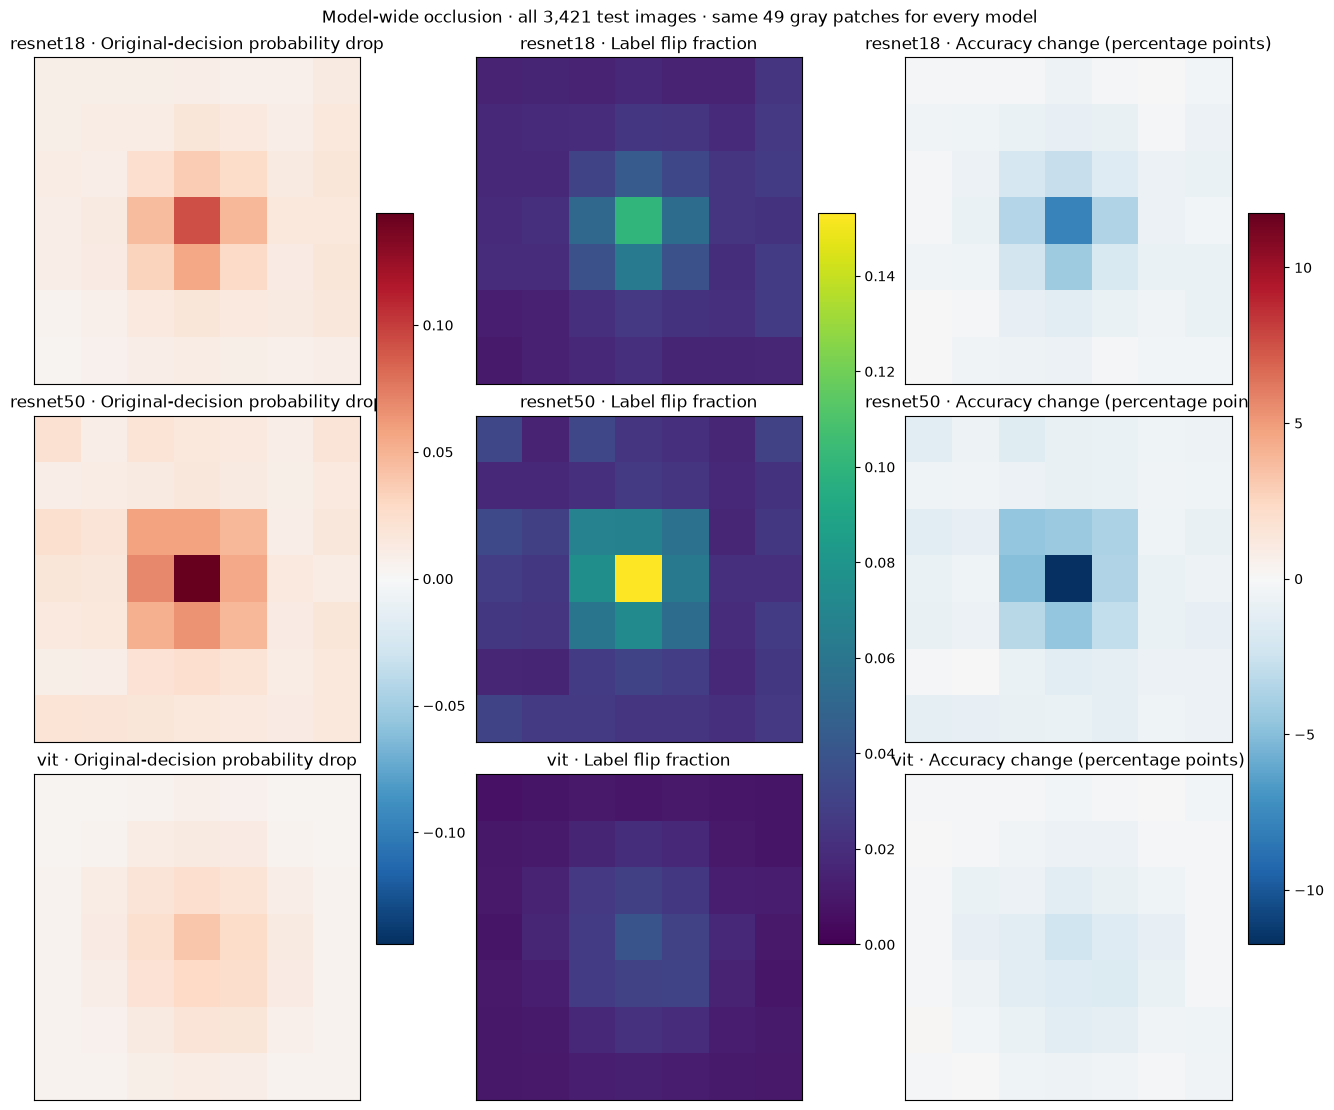

In [31]:
plot_population_overview()

The original decision loses more support under central than outer patches: mean central/outer drops are 0.043/0.011 for ResNet18, 0.066/0.015 for ResNet50 and 0.025/0.008 for ViT. This localizes sensitivity in fixed image coordinates but does not identify a nucleus or an attention mechanism, because the dataset already contains centered crops. The accuracy-change panel summarizes net correctness, while the probability map tracks support for the original decision even when its label is unchanged. Both describe the full test population, not selected errors.

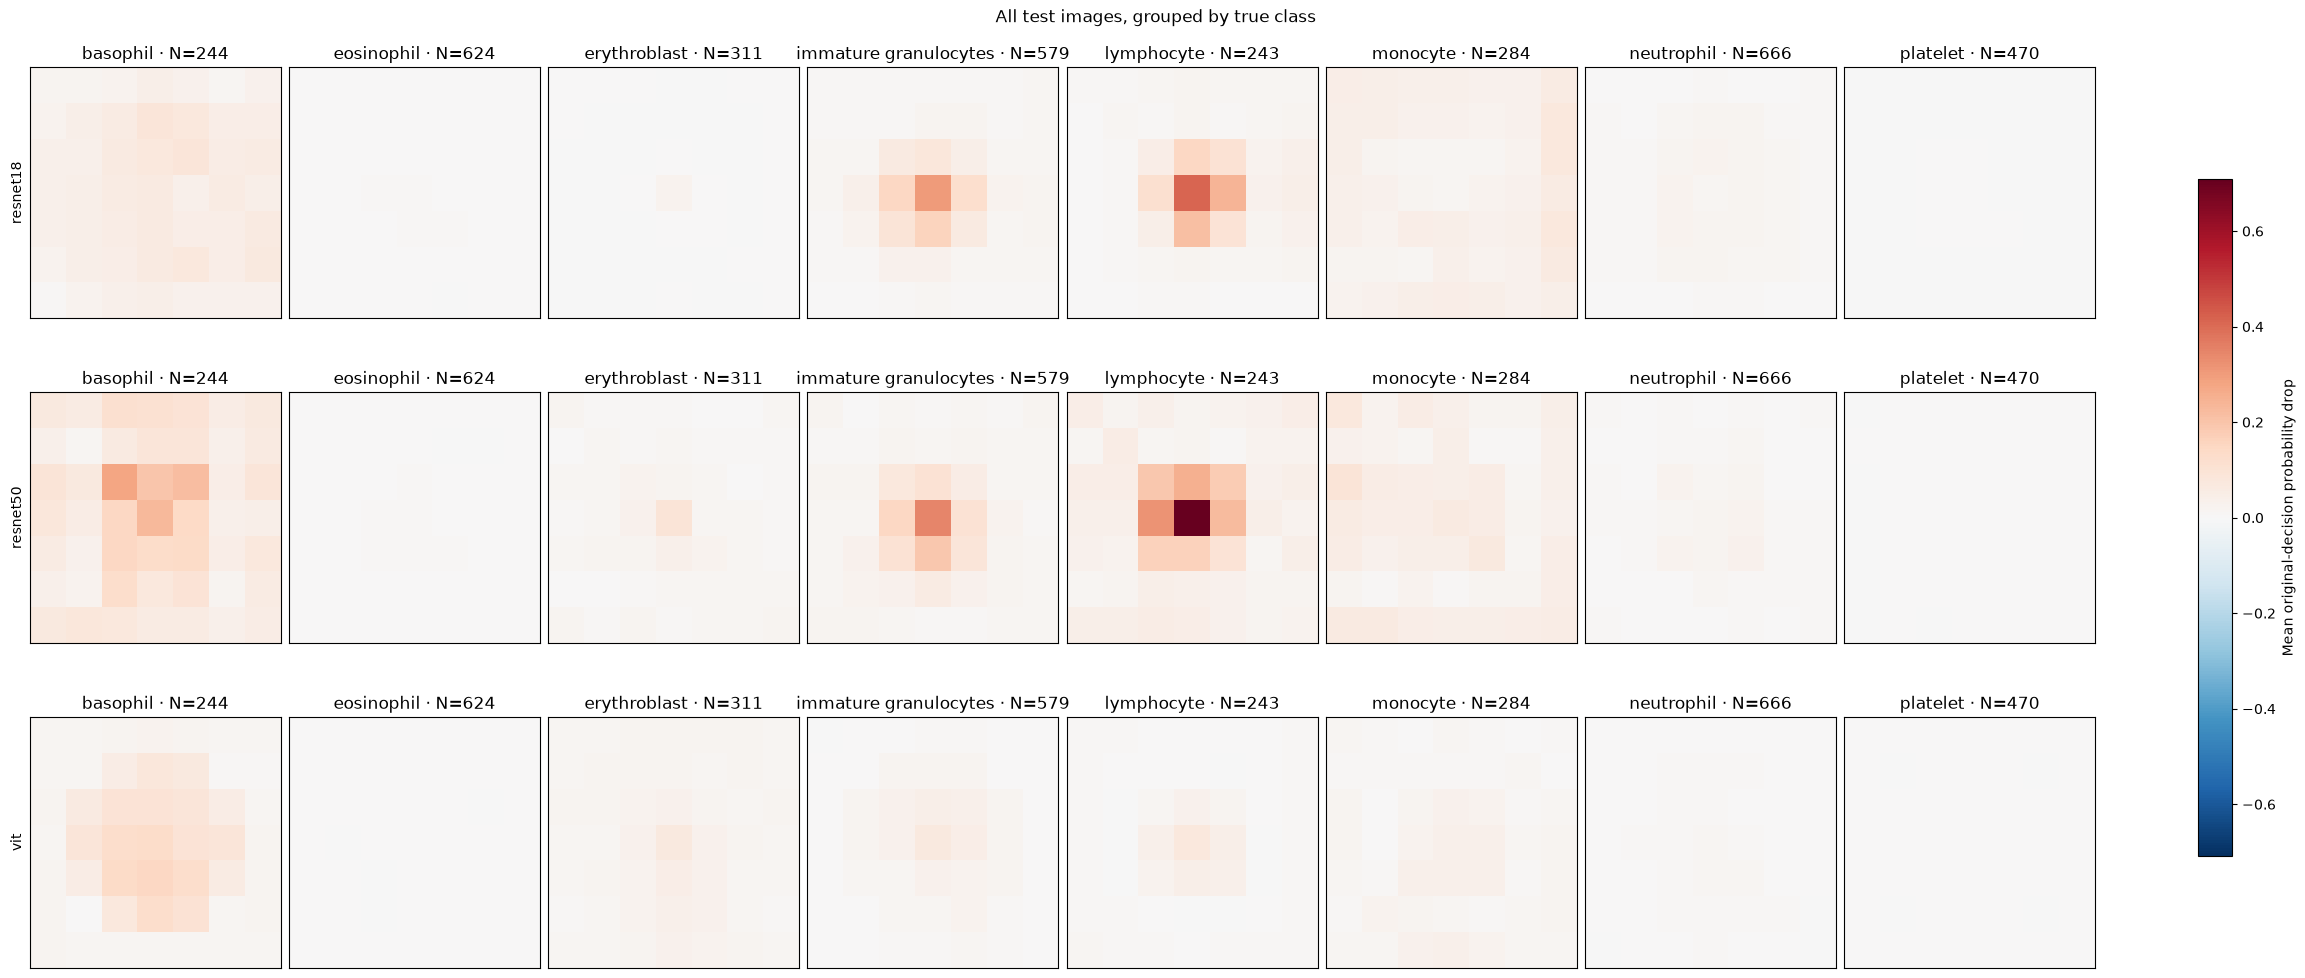

In [32]:
plot_population_classes()

Spatial sensitivity is strongly class-dependent: ResNet50’s mean probability drop is 0.085 for basophils but 0.009 for neutrophils, with almost no change for platelets. These differences remain visible because each class is averaged separately rather than weighted by its frequency in the test set. The maps therefore distinguish class-specific spatial dependence that the single population average would conceal.

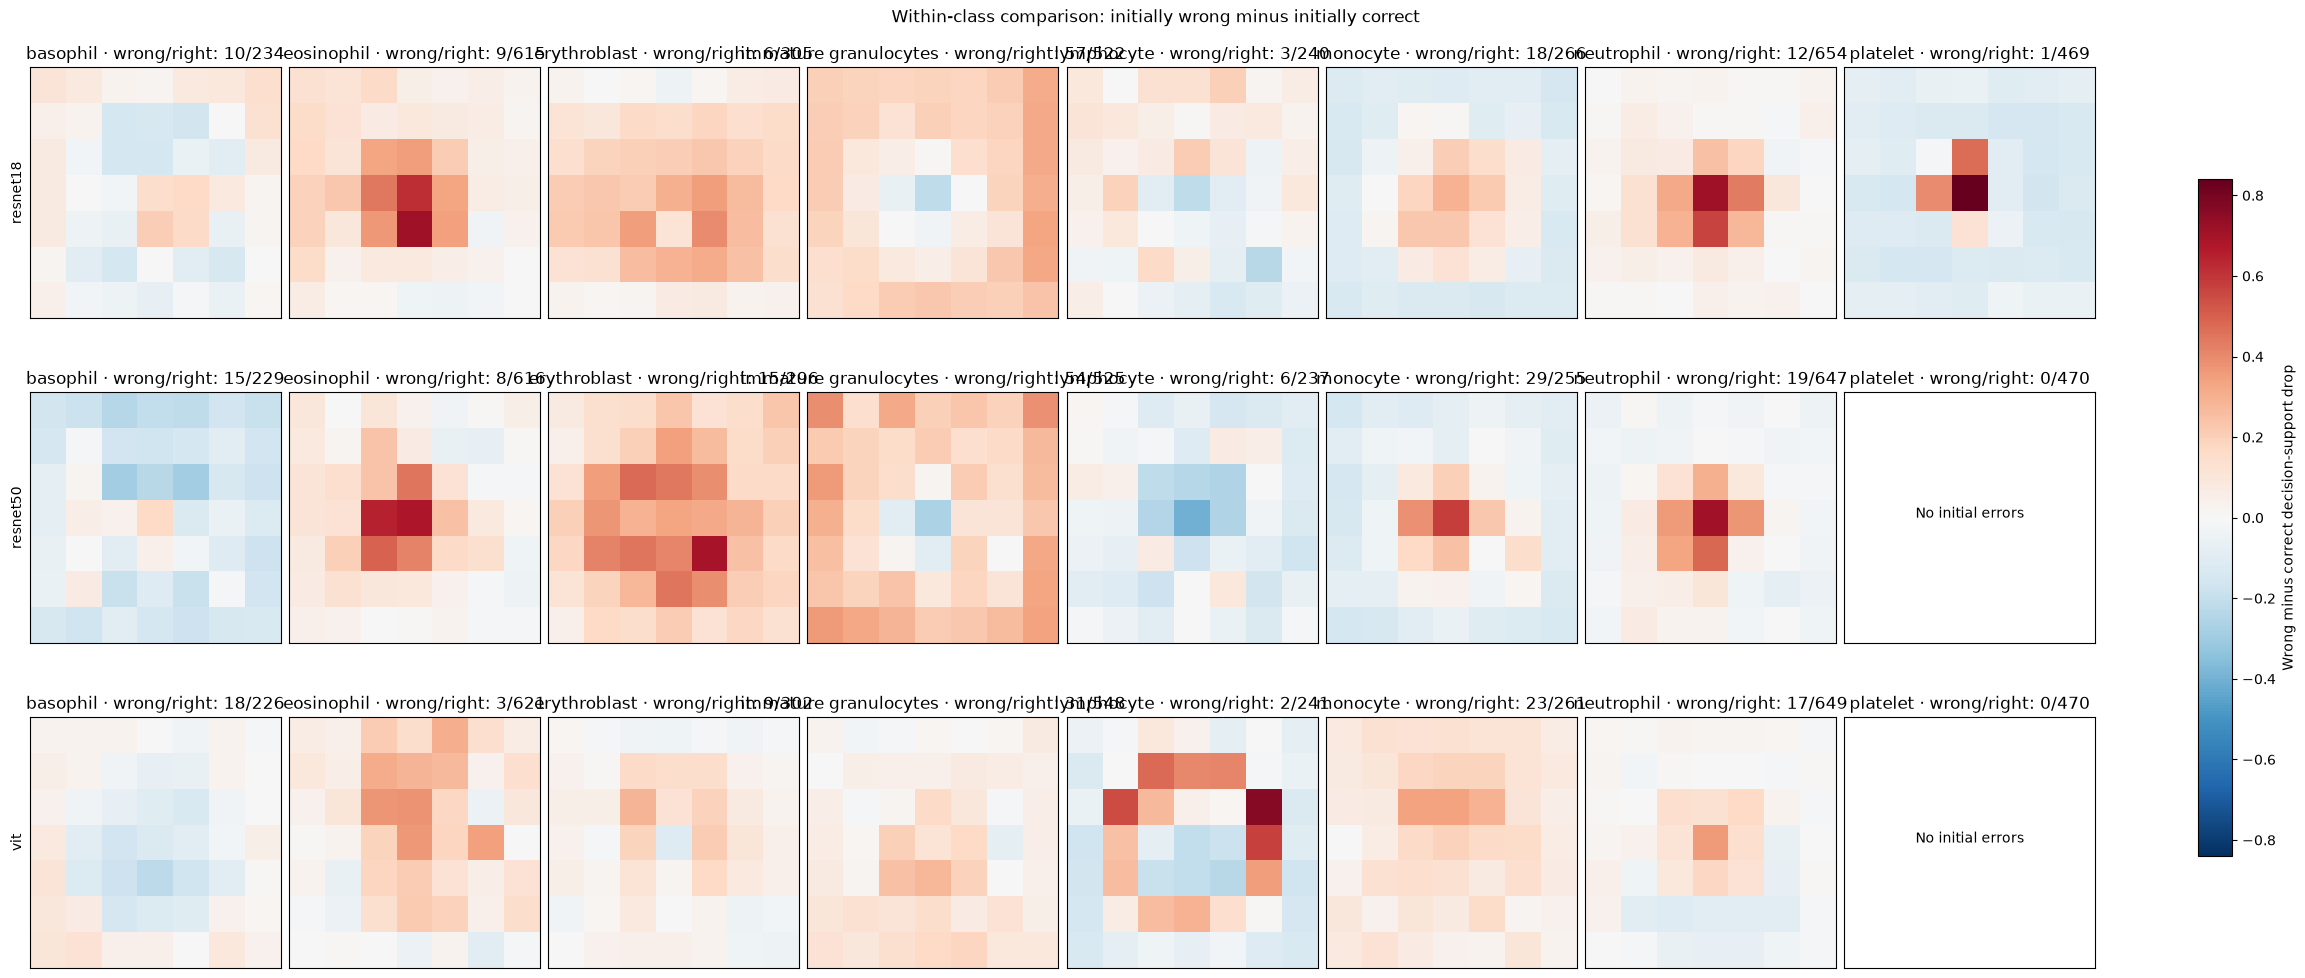

In [33]:
plot_population_classes(difference=True)

Wrong decisions do not show uniformly greater central dependence within every class. For ResNet50, the central wrong-minus-correct drop is +0.212 for monocytes but −0.088 for basophils, so pooling errors would hide opposite class-specific patterns. This comparison uses all original errors, whose starting confidence differs from correct images; the matched high-confidence comparison below tests a more comparable error subgroup.

## High-confidence-error occlusion — conditional subgroup only; the model-wide population analysis is above

In [34]:
# Reuse the full-test predictions, retaining the original subgroup data format.
patch_size = 4
positions = np.array([(y, x) for y in range(0, 28, patch_size) for x in range(0, 28, patch_size)])
occlusion_results, occlusion_drop = [], []
for m, ids in enumerate(error_ids):
    p = population_p[m][:, ids].copy()
    occlusion_results.append(p)
    target = np.take_along_axis(p, predicted[m, ids][None, :, None], axis=-1)[..., 0]
    occlusion_drop.append((confidence[m, ids][None] - target).T.reshape(len(ids), 7, 7))


## Occlusion aggregated by true class and model — all high-confidence errors; original-decision drop and paired error-minus-control contrast; N = images, not patches; fixed image coordinates are not aligned cell structures

In [35]:
occlusion_counts = np.zeros((len(model_names), 8), dtype=int)
occlusion_class_metrics = {name: np.full((len(model_names), 8, 7, 7), np.nan) for name in
                           ['Mean wrong-class probability drop', 'Mean absolute probability change', 'Fraction corrected']}
for m, ids in enumerate(error_ids):
    patch_predictions = occlusion_results[m].argmax(-1).T.reshape(len(ids), 7, 7)
    corrected = patch_predictions == labels[ids, None, None]
    for c in range(8):
        mask = labels[ids] == c
        occlusion_counts[m, c] = mask.sum()
        if mask.any():
            occlusion_class_metrics['Mean wrong-class probability drop'][m, c] = occlusion_drop[m][mask].mean(0)
            occlusion_class_metrics['Mean absolute probability change'][m, c] = np.abs(occlusion_drop[m][mask]).mean(0)
            occlusion_class_metrics['Fraction corrected'][m, c] = corrected[mask].mean(0)
            print(f'{model_names[m]} · {class_names[c]} · N={mask.sum()} · mean absolute effect={np.abs(occlusion_drop[m][mask]).mean():.3f} · correction fraction across patches={corrected[mask].mean():.1%}')

occlusion_matched_ids = [np.stack((ids, neighbor_ids[m][0])) for m, ids in enumerate(error_ids)]
paired = np.full((3, 8, 7, 7), np.nan)
for m, selected in enumerate(occlusion_matched_ids):
    for c in range(8):
        mask = labels[selected[0]] == c
        if mask.any():
            paired[m, c] = (population_drop[m, selected[0, mask]] - population_drop[m, selected[1, mask]]).mean(0)
occlusion_class_metrics['Error minus matched-control probability drop'] = paired

def plot_occlusion_summary(title):
    maps = occlusion_class_metrics[title]
    signed = title != 'Mean absolute probability change' and title != 'Fraction corrected'
    limit = 1 if title == 'Fraction corrected' else max(np.nanmax(np.abs(maps)), 0.01)
    fig, axes = plt.subplots(len(model_names), 8, figsize=(23, 3.5 * len(model_names)), layout='constrained')
    for m in range(len(model_names)):
        for c, ax in enumerate(axes[m]):
            if occlusion_counts[m, c]:
                im = ax.imshow(maps[m, c], cmap='RdBu_r' if signed else 'viridis',
                               vmin=-limit if signed else 0, vmax=limit)
            else:
                ax.set_facecolor('#eeeeee')
                ax.text(0.5, 0.5, 'No images', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(f'{class_names[c]} (N={occlusion_counts[m, c]})', fontsize=8, wrap=True)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[m, 0].set_ylabel(model_names[m])
    fig.colorbar(im, ax=axes, shrink=0.65, label=title)
    fig.suptitle(f'{title} — each square covers 4 × 4 pixels; small classes are descriptive, not reliable comparisons')
    plt.show()

resnet18 · basophil · N=6 · mean absolute effect=0.136 · correction fraction across patches=1.7%
resnet18 · eosinophil · N=6 · mean absolute effect=0.092 · correction fraction across patches=6.8%
resnet18 · erythroblast · N=4 · mean absolute effect=0.075 · correction fraction across patches=5.6%
resnet18 · immature granulocytes · N=36 · mean absolute effect=0.123 · correction fraction across patches=9.0%
resnet18 · monocyte · N=8 · mean absolute effect=0.061 · correction fraction across patches=4.1%
resnet18 · neutrophil · N=10 · mean absolute effect=0.072 · correction fraction across patches=6.1%
resnet50 · basophil · N=10 · mean absolute effect=0.075 · correction fraction across patches=0.6%
resnet50 · eosinophil · N=4 · mean absolute effect=0.103 · correction fraction across patches=5.1%
resnet50 · erythroblast · N=6 · mean absolute effect=0.136 · correction fraction across patches=12.6%
resnet50 · immature granulocytes · N=28 · mean absolute effect=0.147 · correction fraction acros

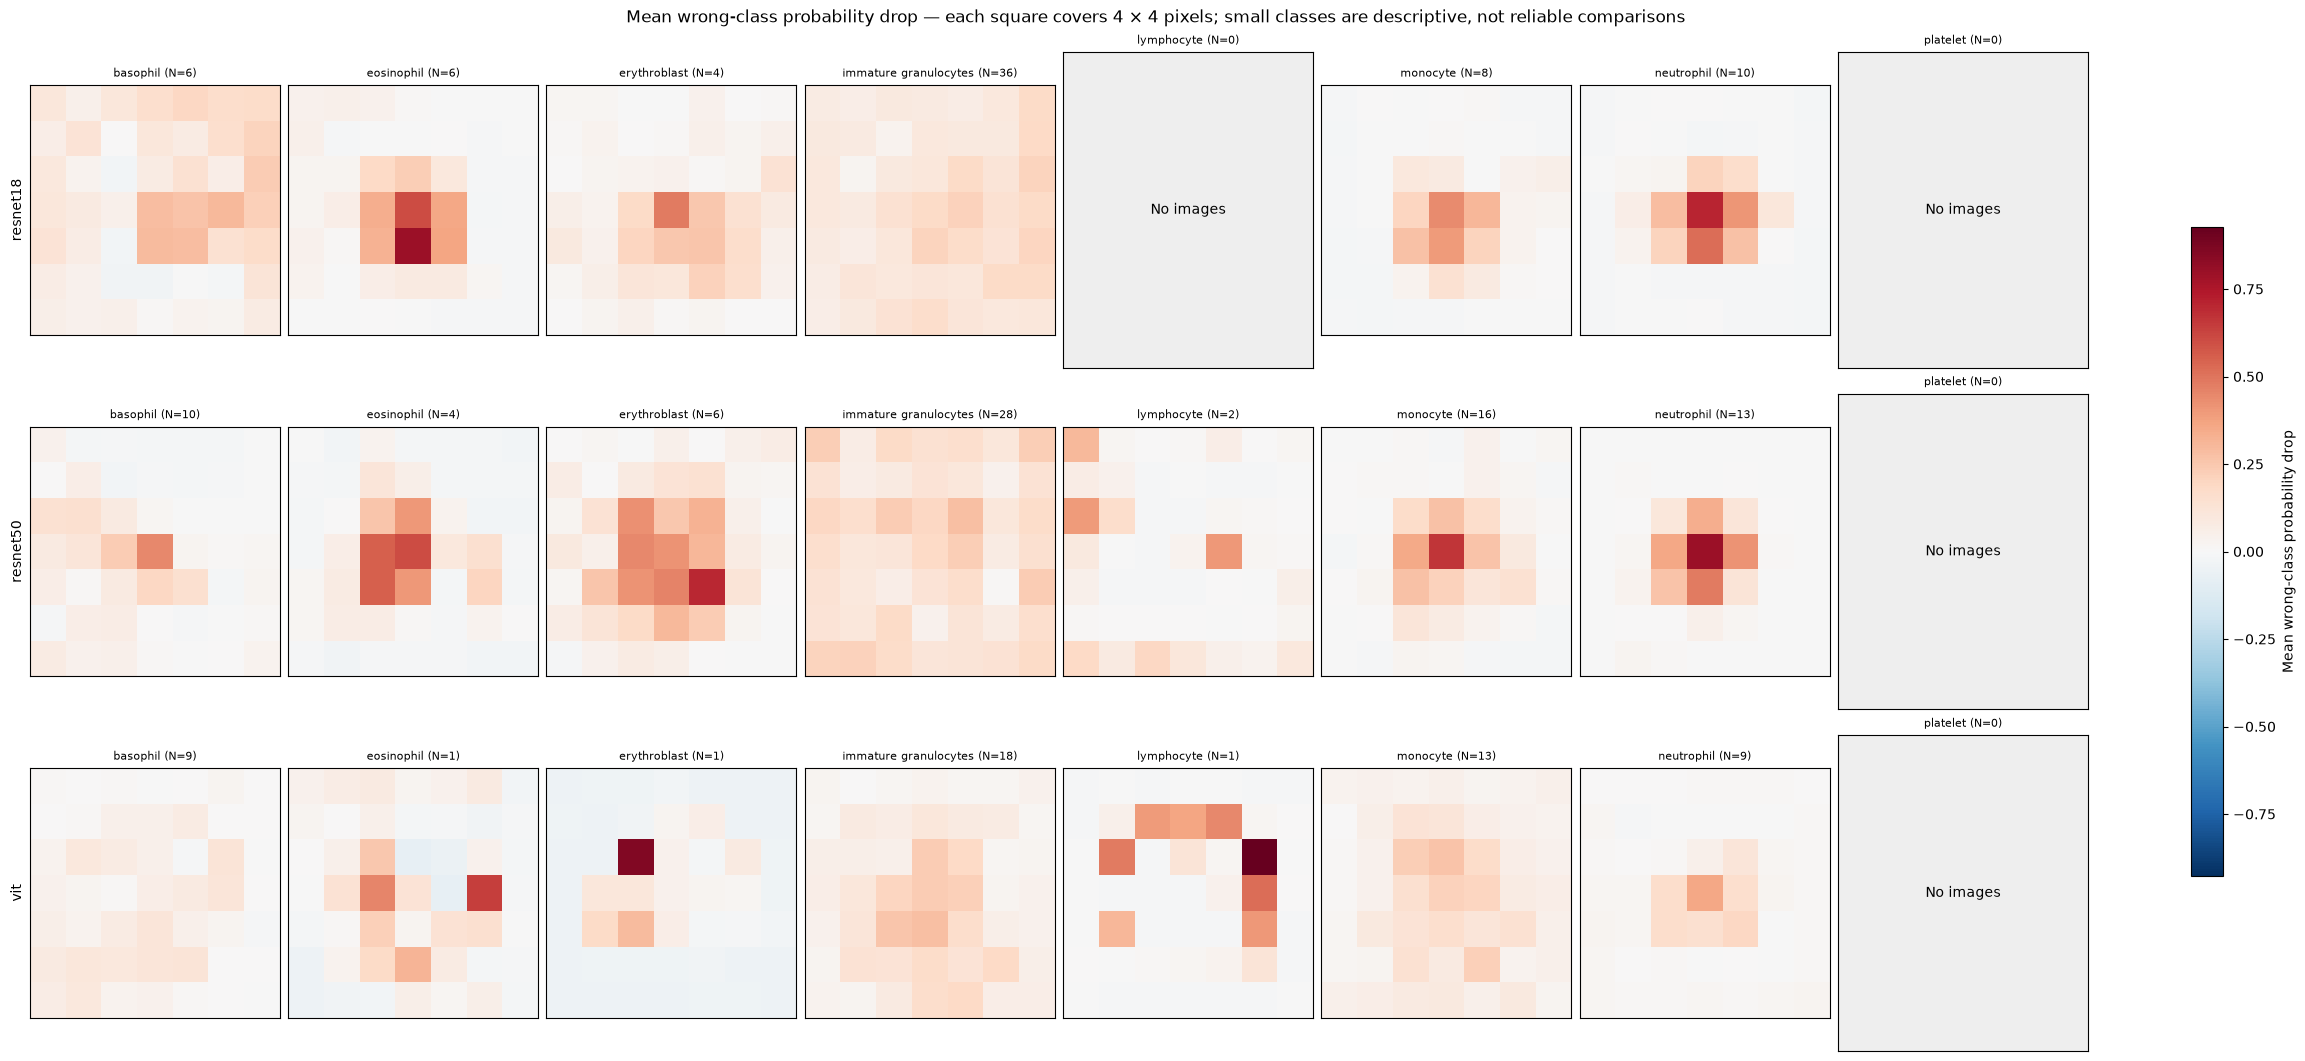

In [36]:
plot_occlusion_summary('Mean wrong-class probability drop')

These maps condition on high-confidence errors rather than the full population. Central dependence alone is not distinctive: centered crops also give central effects among correct images. The following paired contrast asks the relevant question—whether the original wrong decisions depend more strongly on the same occluded locations than class-matched correct decisions.

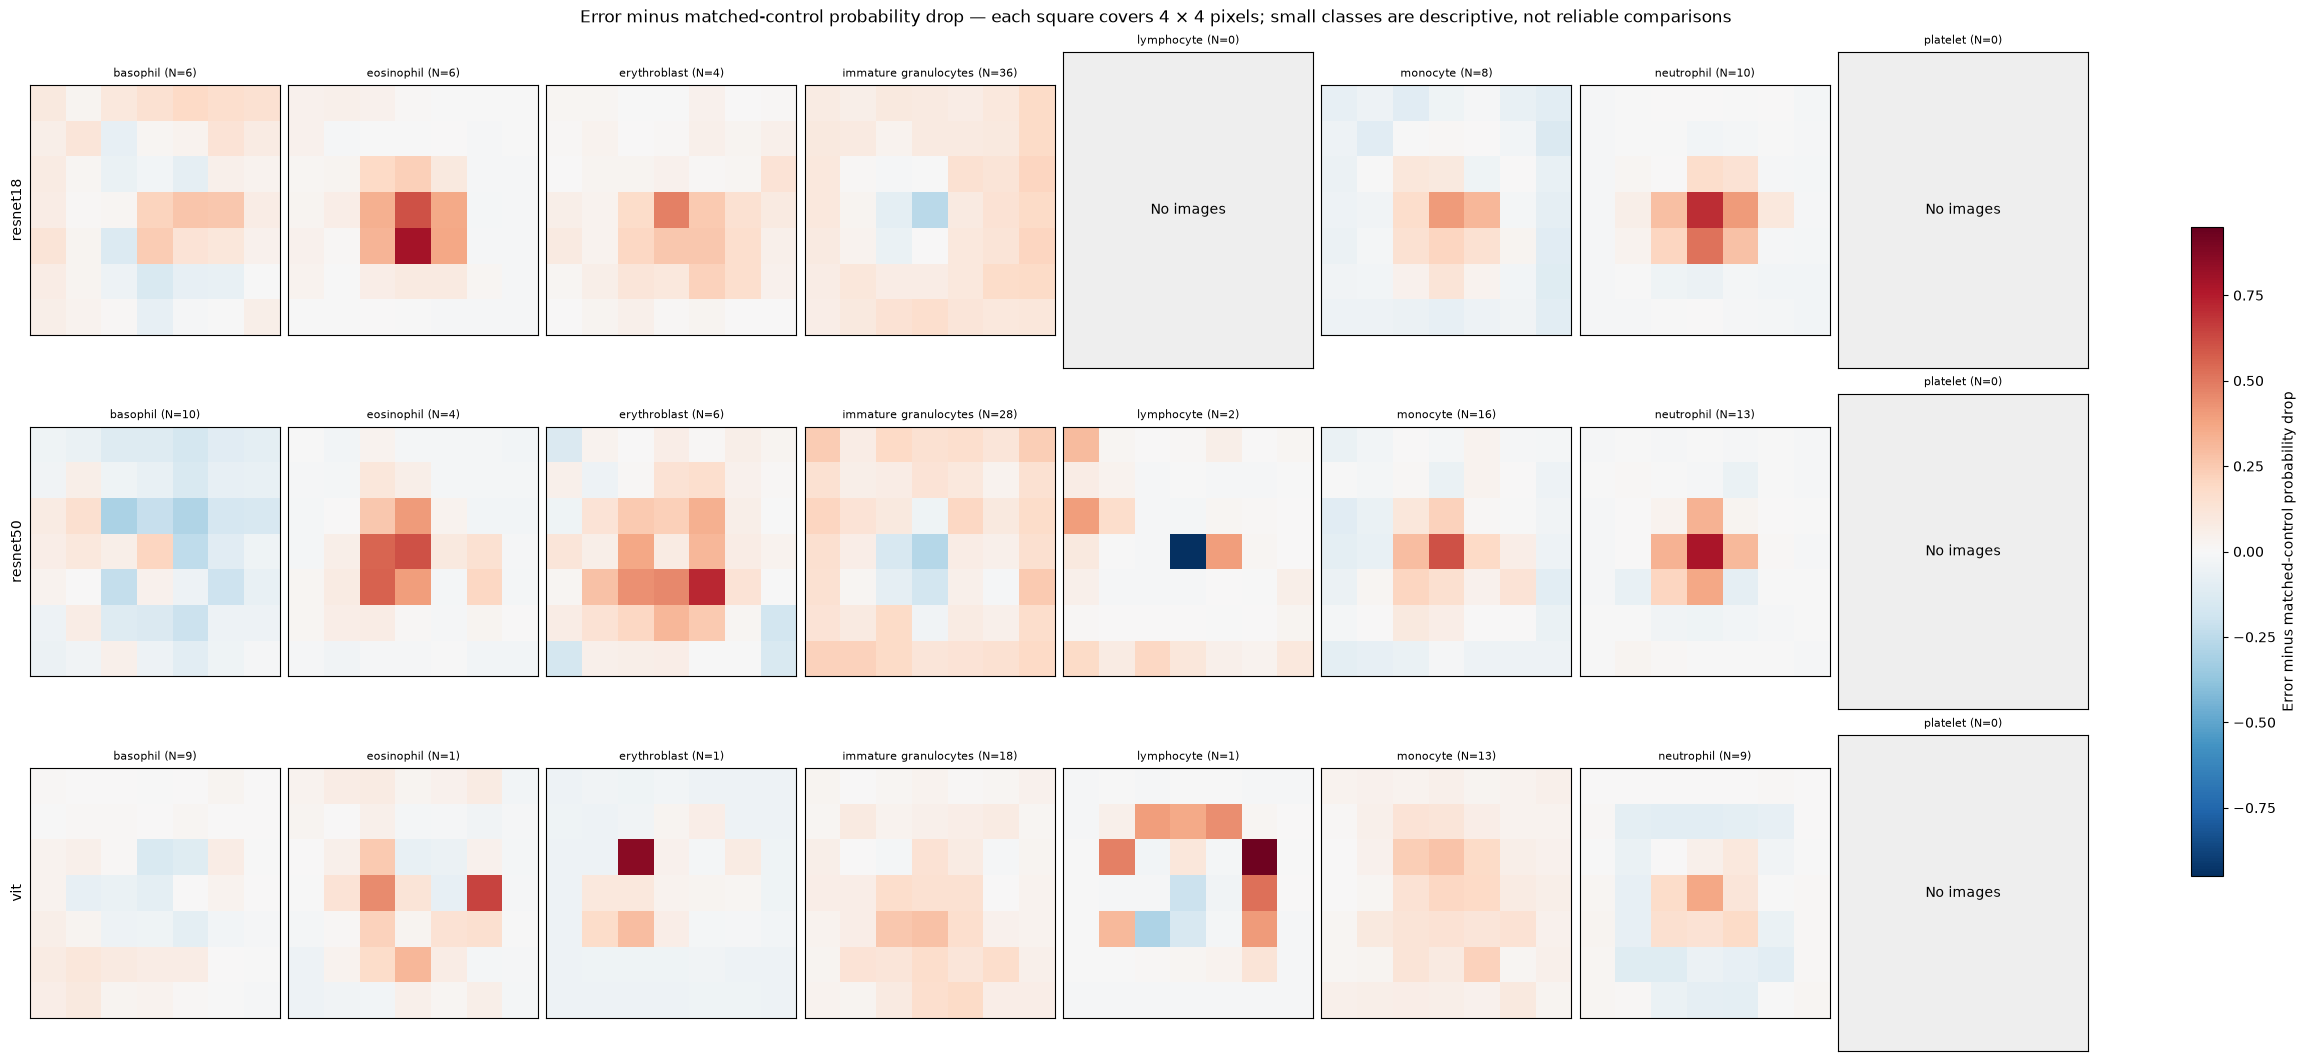

In [37]:
plot_occlusion_summary('Error minus matched-control probability drop')

Compared with their matched correct controls, high-confidence errors show an additional central probability drop of 0.104 for ResNet18, 0.098 for ResNet50 and 0.113 for ViT. This separates the error-specific dependence from the central sensitivity already present in the dataset. The comparison holds true class and confidence threshold fixed, but targets each image’s own original decision and does not match confidence exactly; it is evidence of differential dependence, not anatomical attribution.

## Save all high-confidence-error analysis data — all examples and all intervention probabilities, not just the displayed selections

In [38]:
analysis = dict(shared_indices=shared, union_indices=union, threshold=threshold, split='test',
                model_names=model_names, class_names=class_names, features=features, feature_names=feature_names,
                checkpoints=checkpoints, model_input_resolutions=[224, 28, 224],
                pair_overlap=pair_overlap, pair_jaccard=pair_jaccard,
                feature_sample_index=np.arange(len(labels)), true_labels=labels, baseline_probabilities=probabilities,
                control_weights=np.stack(control_weights), feature_effects=np.stack(feature_effects),
                saturation_levels=saturation_levels, occlusion_positions=positions, patch_size=patch_size,
                occlusion_fill_rgb=[128, 128, 128], neighbor_roles=['true_class', 'predicted_class'],
                saturation_roles=['high_confidence_errors', 'matched_correct_controls'],
                occlusion_class_counts=occlusion_counts, occlusion_grouping='true_class',
                **{f'occlusion_class_{name}': maps for name, maps in occlusion_class_metrics.items()})
for m, name in enumerate(model_names):
    for key, value in dict(error_ids=error_ids[m], confusion=confusions[m], selected_examples=example_ids[m],
                           neighbor_ids=neighbor_ids[m], neighbor_rmse=neighbor_rmse[m],
                           saturation_ids=saturation_ids[m], saturation_probabilities=saturation_results[m],
                           occlusion_probabilities=occlusion_results[m], occlusion_drop=occlusion_drop[m]).items():
        analysis[f'{name}_{key}'] = value
    if len(error_ids[m]):
        j = np.abs(feature_effects[m]).argmax()
        corrections = (saturation_results[m][0].argmax(-1) == labels[error_ids[m]]).sum(-1)
        print(f'{name}: largest descriptive feature shift: {feature_names[j]} ({feature_effects[m][j]:+.2f} control SD)')
        control_errors = (saturation_results[m][1].argmax(-1) != labels[saturation_ids[m][1]]).sum(-1)
        print('Saturation factor / corrected errors / newly wrong matched control pairs:', list(zip(saturation_levels.round(2).tolist(), corrections.tolist(), control_errors.tolist())))
        involved = ((labels[error_ids[m]] == 3) | (predicted[m, error_ids[m]] == 3)).sum()
        print(f'{name}: immature granulocytes occur on either side of {involved}/{len(error_ids[m])} error pairs')
        print(f'{name}: mean largest wrong-class probability drop per image under occlusion: {occlusion_drop[m].max((1, 2)).mean():.3f}')
path = Path('predictions/high_confidence_error_analysis.npz')
np.savez_compressed(path, **analysis)
print(path)
print('Hypotheses to investigate: appearance/staining sensitivity in a subset of errors; visual ambiguity around immature-granulocyte confusions. Saturation can also damage correct controls, so correction counts alone are not evidence of improvement.')
print('Exploratory only: correlated color features, class composition, pixel alignment, unequal neighbor-pool sizes and artificial interventions prevent causal or biological conclusions. Validate hypotheses on new images, not these selected errors.')

resnet18: largest descriptive feature shift: Mean blue (+0.40 control SD)
Saturation factor / corrected errors / newly wrong matched control pairs: [(0.5, 5, 66), (0.6, 5, 58), (0.7, 8, 48), (0.8, 12, 24), (0.9, 5, 6), (1.0, 0, 0), (1.1, 7, 0), (1.2, 15, 7), (1.3, 22, 13), (1.4, 26, 16), (1.5, 27, 21)]
resnet18: immature granulocytes occur on either side of 58/70 error pairs
resnet18: mean largest wrong-class probability drop per image under occlusion: 0.682
resnet50: largest descriptive feature shift: Boundary gradient fraction (-0.29 control SD)
Saturation factor / corrected errors / newly wrong matched control pairs: [(0.5, 6, 73), (0.6, 7, 72), (0.7, 10, 49), (0.8, 15, 20), (0.9, 14, 4), (1.0, 0, 0), (1.1, 7, 6), (1.2, 13, 15), (1.3, 14, 25), (1.4, 15, 32), (1.5, 16, 43)]
resnet50: immature granulocytes occur on either side of 61/79 error pairs
resnet50: mean largest wrong-class probability drop per image under occlusion: 0.761
vit: largest descriptive feature shift: Boundary gradi

## A · Shared and exclusive errors — all 39 shared errors; mark cases with ≥90% confidence in every model; class IDs listed below

Shared errors: 39 with ≥90% confidence in all models: 18
Classes: {0: np.str_('basophil'), 1: np.str_('eosinophil'), 2: np.str_('erythroblast'), 3: np.str_('immature granulocytes'), 4: np.str_('lymphocyte'), 5: np.str_('monocyte'), 6: np.str_('neutrophil'), 7: np.str_('platelet')}


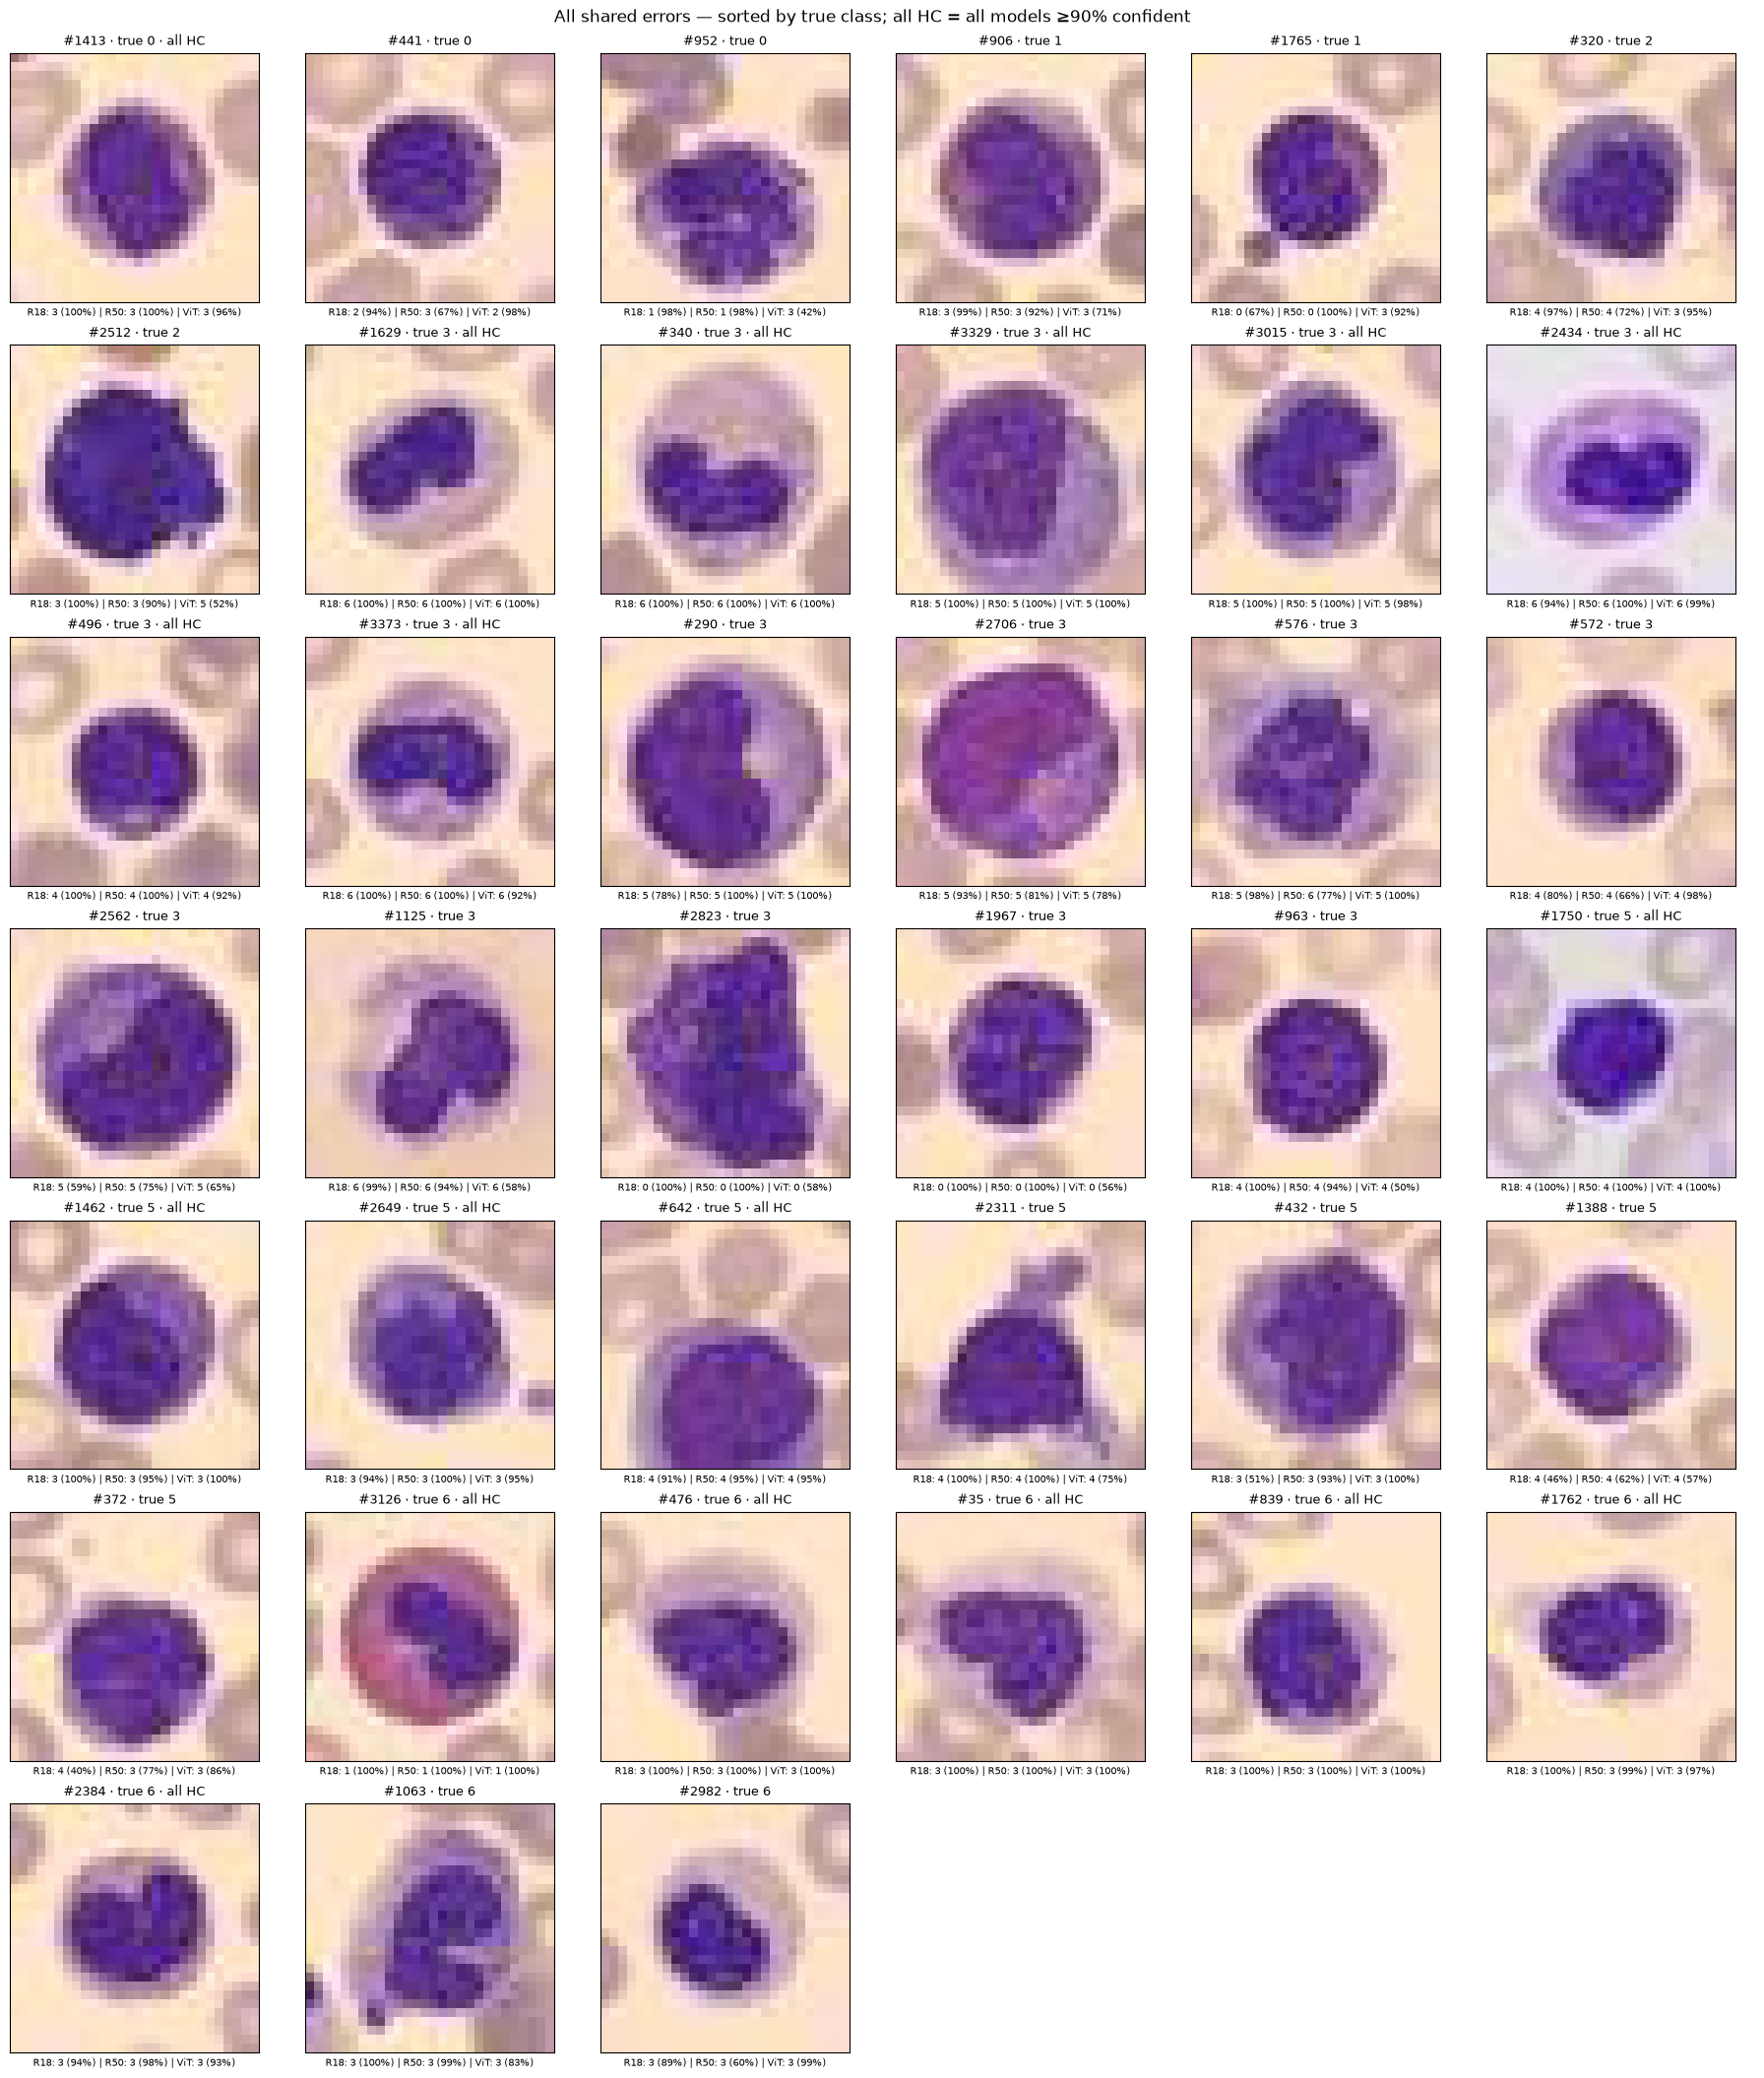

In [39]:
wrong = ~correct
high_wrong = wrong & (confidence >= threshold)
common_wrong = np.flatnonzero(wrong.all(0))
common_hc = np.flatnonzero(high_wrong.all(0))
exclusive_hc = [np.flatnonzero(high_wrong[m] & (wrong.sum(0) == 1)) for m in range(len(model_names))]
print('Shared errors:', len(common_wrong), 'with ≥90% confidence in all models:', len(common_hc))
print('Classes:', dict(enumerate(class_names)))

def gallery(ids, title, columns=6):
    rows = max(1, int(np.ceil(len(ids) / columns)))
    fig, axes = plt.subplots(rows, columns, figsize=(18, 3 * rows), squeeze=False, layout='constrained')
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, ids):
        ax.axis('on')
        ax.imshow(images[i])
        ax.set_title(f'#{i} · true {labels[i]}' + (' · all HC' if high_wrong[:, i].all() else ''), fontsize=9)
        ax.set_xlabel(' | '.join(f'{name}: {predicted[m, i]} ({confidence[m, i]:.0%})'
                                for m, name in enumerate(['R18', 'R50', 'ViT'])), fontsize=7, wrap=True)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(title)
    plt.show()

order = np.lexsort((-confidence[:, common_wrong].min(0), labels[common_wrong]))
gallery(common_wrong[order], 'All shared errors — sorted by true class; all HC = all models ≥90% confident')

All three models misclassify these 39 images; the 18 marked “all HC” receive at least 90% confidence from every model. All three choose the same wrong class on those 18, and nine confuse immature granulocytes with neutrophils or vice versa. The repeated class patterns make these useful cases for independent image and label review, rather than assuming model agreement confirms the label.

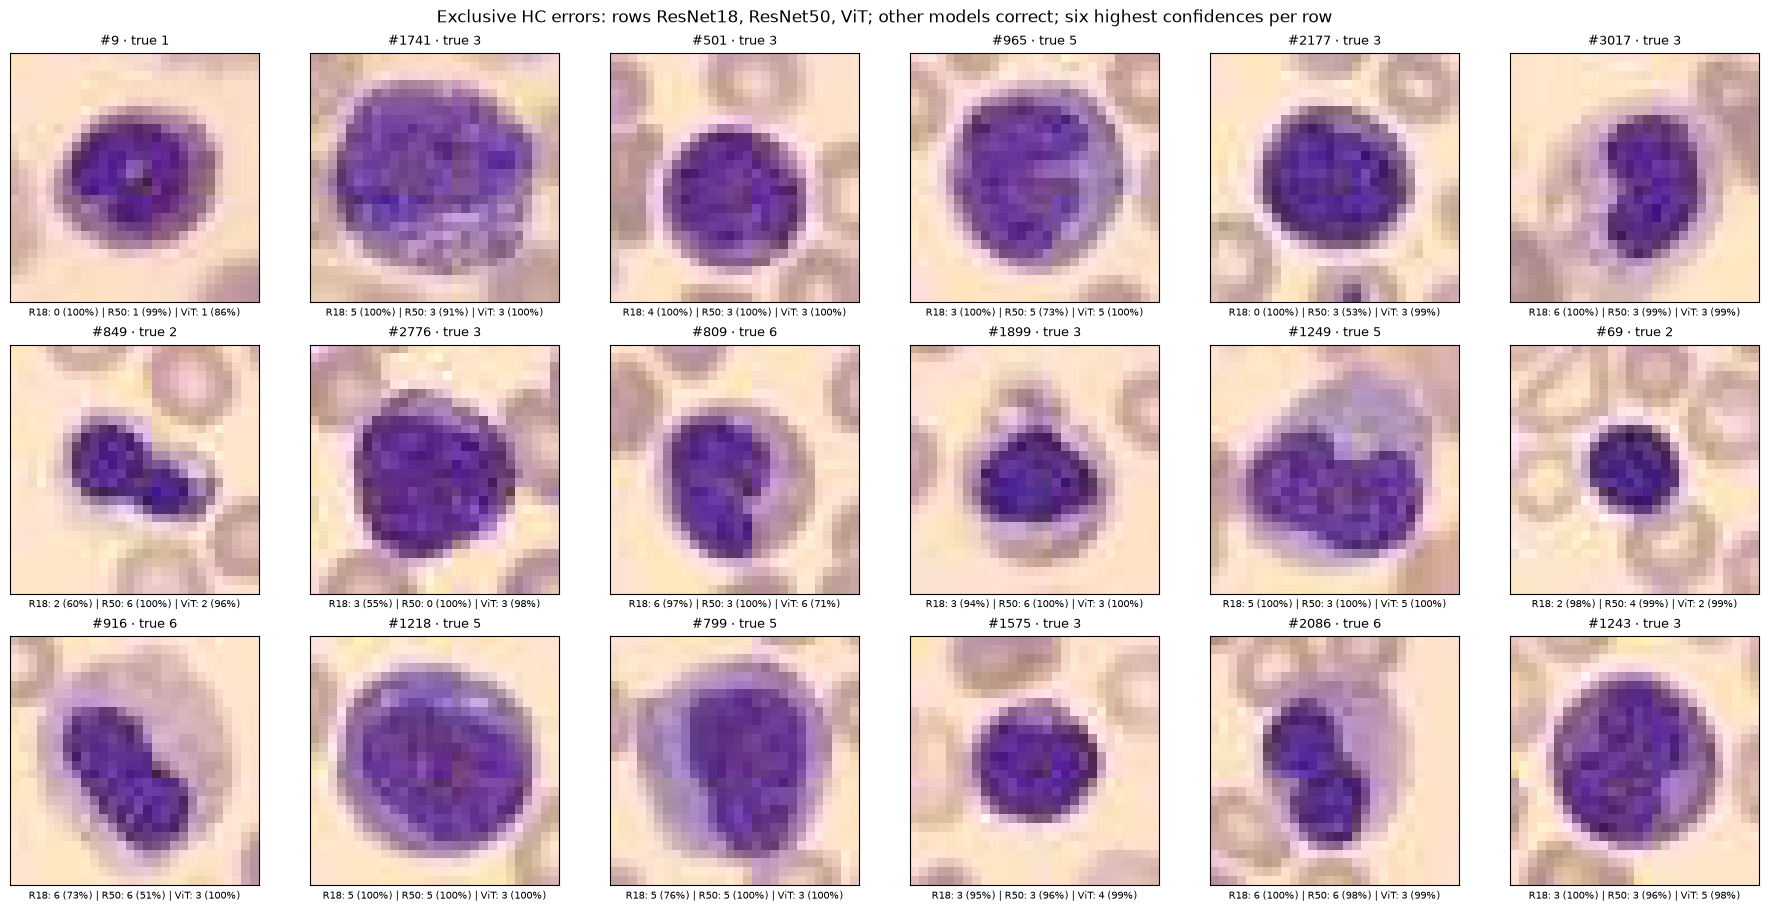

In [40]:
exclusive_examples = np.concatenate([ids[np.argsort(-confidence[m, ids], kind='stable')[:6]]
                                     for m, ids in enumerate(exclusive_hc)])
gallery(exclusive_examples, 'Exclusive HC errors: rows ResNet18, ResNet50, ViT; other models correct; six highest confidences per row')

These rows show errors made only by ResNet18, only by ResNet50 and only by ViT, while the other two models are correct. Their existence suggests some complementary behavior, but does not show that voting would solve the shared failures above. The examples were selected by confidence, not to represent the usual appearance of each error group.

## A · Matched images — errors beside similar same-class controls classified correctly with ≥90% confidence by every model

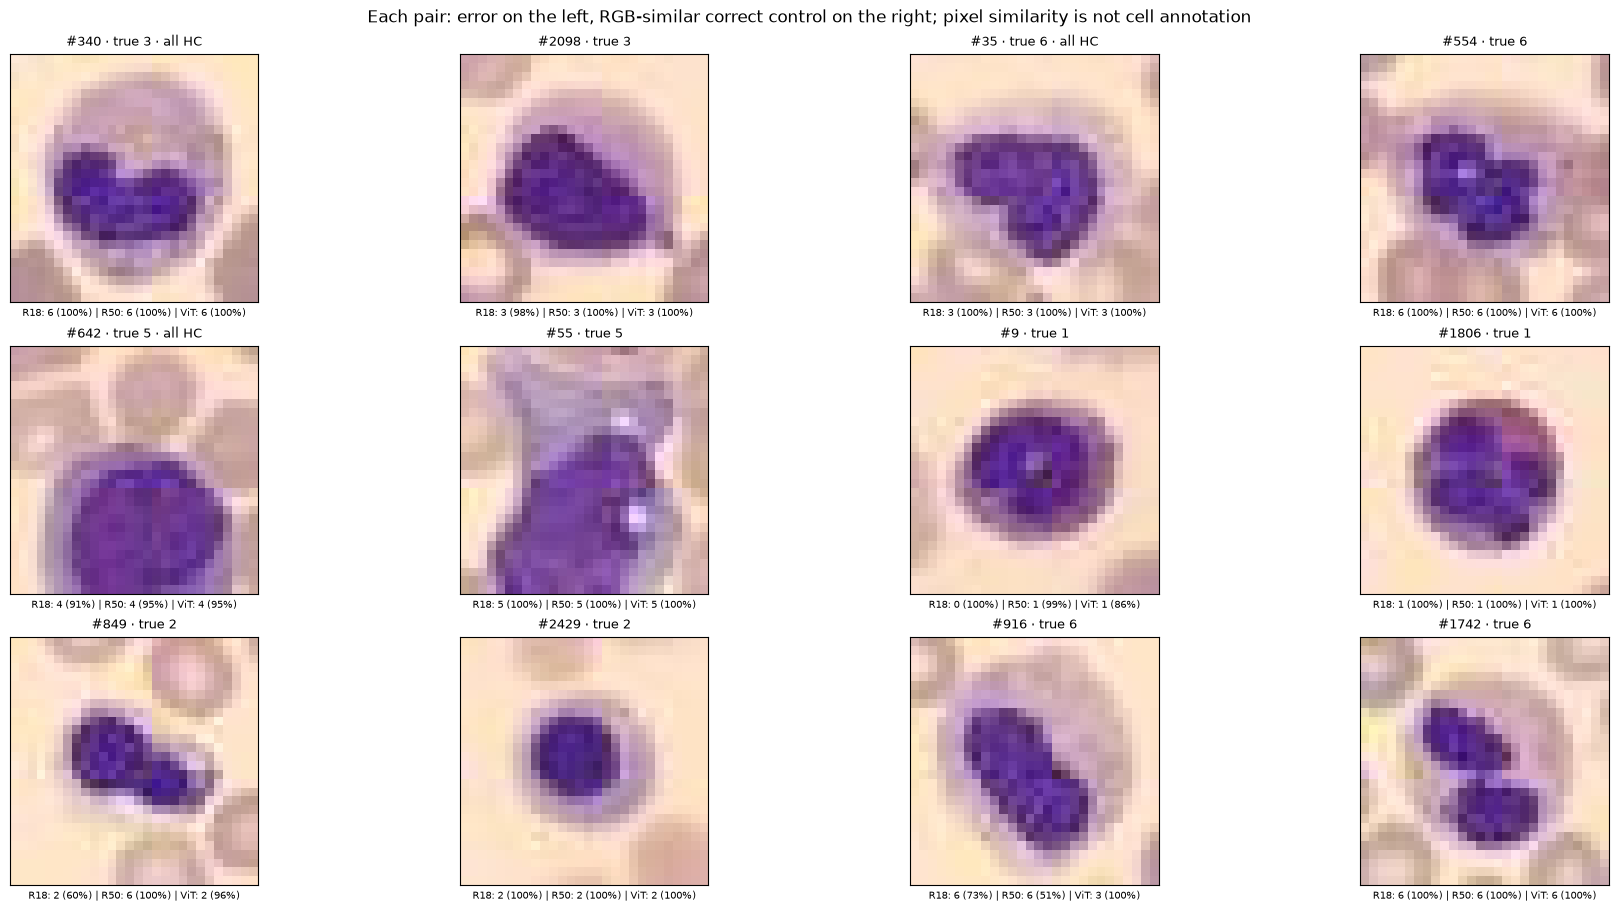

In [41]:
clean = correct.all(0) & (confidence >= threshold).all(0)
largest_classes = np.argsort(-np.bincount(labels[common_hc], minlength=8))[:3]
selected_errors = [common_hc[labels[common_hc] == c][0] for c in largest_classes if (labels[common_hc] == c).any()]
selected_errors += [ids[np.argmax(confidence[m, ids])] for m, ids in enumerate(exclusive_hc) if len(ids)]
gallery_pairs = []
for i in selected_errors:
    allowed = clean & (labels == labels[i])
    assert allowed.any()
    distance = squared + squared[i] - 2 * flat @ flat[i]
    control = np.where(allowed, distance, np.inf).argmin()
    gallery_pairs.append([i, control])
gallery_pairs = np.array(gallery_pairs)
gallery(gallery_pairs.ravel(), 'Each pair: error on the left, RGB-similar correct control on the right; pixel similarity is not cell annotation', columns=4)

The paired images can look similar in broad color and layout while receiving different decisions, as illustrated by cases #340/#2098 and #35/#554. This weakens a simple explanation that every error has an obviously unusual overall appearance. Differences in dark structures are worth investigating, but RGB matching is sensitive to alignment and is not a substitute for expert cell annotation.

## B · Hypotheses: class concentration and image features — error rate per true class; features versus class-matched controls correct and confident in every model

In [42]:
class_sizes = np.bincount(labels, minlength=8)
class_hc_counts = np.stack([np.bincount(labels[ids], minlength=8) for ids in error_ids])
class_hc_rates = class_hc_counts / class_sizes
cohorts = [common_hc, *exclusive_hc]
cohort_names = ['All three HC wrong', *[f'Only {name} HC wrong' for name in model_names]]
cohort_effects, cohort_weights = [], []
for ids in cohorts:
    weights = np.zeros(len(labels))
    for c in np.unique(labels[ids]):
        mask = clean & (labels == c)
        assert mask.any()
        weights[mask] = (labels[ids] == c).mean() / mask.sum()
    mean = np.average(features, axis=0, weights=weights)
    std = np.sqrt(np.average((features - mean) ** 2, axis=0, weights=weights))
    cohort_effects.append((features[ids].mean(0) - mean) / np.maximum(std, 1e-12))
    cohort_weights.append(weights)
cohort_effects = np.stack(cohort_effects)

def plot_class_rates():
    fig, ax = plt.subplots(figsize=(13, 4), layout='constrained')
    im = ax.imshow(class_hc_rates, cmap='Oranges', vmin=0, aspect='auto')
    ax.set(xticks=range(8), xticklabels=class_names, yticks=range(3), yticklabels=model_names)
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    for m in range(3):
        for c in range(8):
            ax.text(c, m, f'{class_hc_rates[m, c]:.1%} ({class_hc_counts[m, c]}/{class_sizes[c]})', ha='center', fontsize=8)
    fig.colorbar(im, ax=ax, label='Fraction of ≥90%-confident errors within each true class')
    plt.show()

def plot_shared_features():
    fig, ax = plt.subplots(figsize=(12, 5), layout='constrained')
    limit = max(np.abs(cohort_effects).max(), 0.01)
    im = ax.imshow(cohort_effects, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
    ax.set(xticks=range(7), xticklabels=feature_names, yticks=range(4),
           yticklabels=[f'{name} (N={len(ids)})' for name, ids in zip(cohort_names, cohorts)])
    plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
    for row in range(4):
        for col in range(7):
            ax.text(col, row, f'{cohort_effects[row, col]:+.2f}', ha='center')
    fig.colorbar(im, ax=ax, label='Error minus correct control, in control standard deviations')
    plt.show()

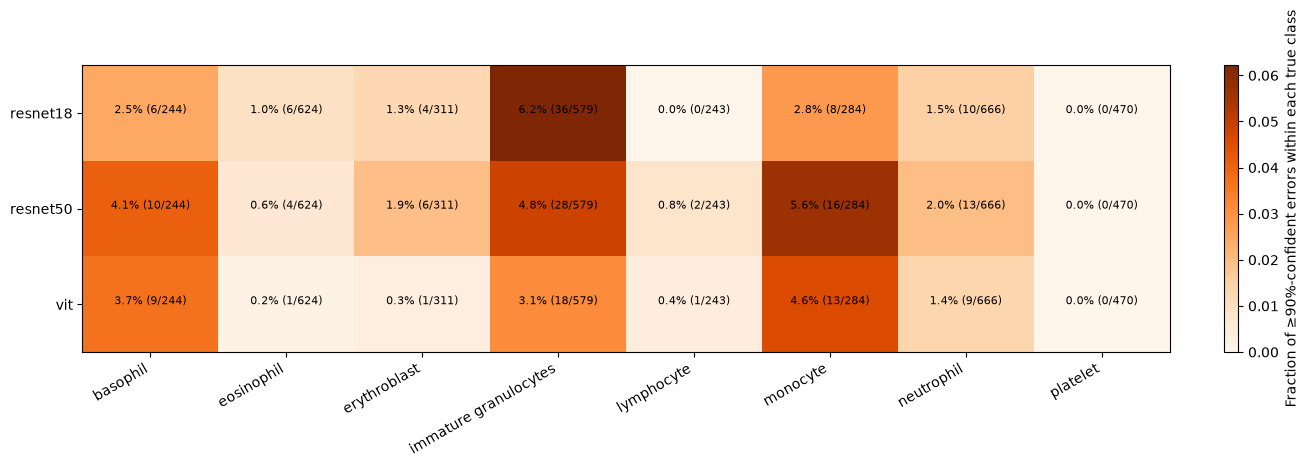

In [43]:
plot_class_rates()

The class-rate view confirms that frequency alone does not explain the error pattern: ResNet18 makes high-confidence errors on 6.22% of immature-granulocyte images, compared with 2.05% overall. Monocytes have the highest rates for ResNet50 and ViT, at 5.63% and 4.58%. The different rankings suggest checkpoint-specific weaknesses rather than one universally difficult class.

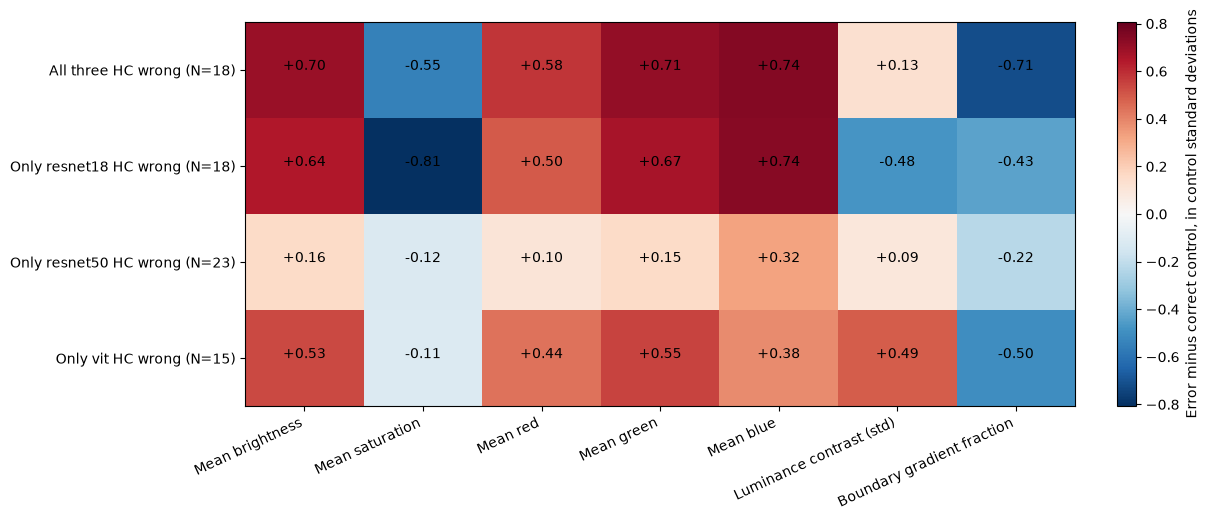

In [44]:
plot_shared_features()

The shared high-confidence errors are brighter (+0.70 control SD), have higher blue values (+0.74 SD) and lower saturation (−0.55 SD) than class-matched confident correct controls. The exclusive groups do not show identical feature profiles, so there is no single appearance signature for all failures. These differences motivate testing brightness and staining-related changes separately, while controlling for their correlation and checking new errors in correct images.

## PCA of all test images — aligned true/predicted-class views of the derived high-confidence-error cohort

In [45]:
pca_path = Path('predictions/test_pca.npz')
if not pca_path.exists():
    from pathlib import Path
    import hashlib
    import numpy as np
    from sklearn.decomposition import PCA
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.metrics import balanced_accuracy_score
    from threadpoolctl import threadpool_limits

    ROOT = Path('.')
    with np.load(ROOT/'data/bloodmnist.npz', allow_pickle=False) as z:
        images, labels = z['test_images'], z['test_labels'].ravel()
    with np.load(ROOT/'predictions/high_confidence_error_analysis.npz', allow_pickle=False) as z:
        probabilities, model_names, class_names = z['baseline_probabilities'], z['model_names'], z['class_names']
    anchor_pairs = gallery_pairs[:2]
    x = images.reshape(len(images), -1).astype(np.float32) / 255
    indices = np.arange(len(x))
    train, holdout = train_test_split(indices, test_size=0.25, random_state=42, stratify=labels)
    with threadpool_limits(limits=4):
        pca = PCA(n_components=2, svd_solver='randomized', random_state=42)
        xy = pca.fit_transform(x)
        validation_pca = PCA(n_components=2, svd_solver='randomized', random_state=42)
        validation_train = validation_pca.fit_transform(x[train])
        validation_holdout = validation_pca.transform(x[holdout])
        lower, upper = xy.min(0), xy.max(0)
        padding = (upper - lower) * 0.05
        gx, gy = np.meshgrid(np.linspace(lower[0]-padding[0],upper[0]+padding[0],160),
                             np.linspace(lower[1]-padding[1],upper[1]+padding[1],160))
        grid = np.column_stack((gx.ravel(),gy.ravel()))
        predicted = probabilities.argmax(-1)
        grid_labels, agreement, balanced_agreement, majority_agreement = [], [], [], []
        for m in range(len(model_names)):
            surrogate = KNeighborsClassifier(n_neighbors=25, weights='distance')
            surrogate.fit(validation_train, predicted[m, train])
            guesses = surrogate.predict(validation_holdout)
            agreement.append((guesses == predicted[m, holdout]).mean())
            balanced_agreement.append(balanced_accuracy_score(predicted[m, holdout], guesses))
            majority = np.bincount(predicted[m, train],minlength=8).argmax()
            majority_agreement.append((predicted[m, holdout] == majority).mean())
            surrogate.fit(xy, predicted[m])
            grid_labels.append(surrogate.predict(grid).reshape(gx.shape))
        # Suppress unsupported low-density regions rather than extrapolating across the full rectangle.
        density_threshold = np.quantile(surrogate.kneighbors(xy, n_neighbors=6)[0][:,5],0.95)
        support = surrogate.kneighbors(grid,n_neighbors=5)[0][:,4] <= density_threshold
        residual = x[anchor_pairs.ravel()] - pca.inverse_transform(xy[anchor_pairs.ravel()])
        np.testing.assert_allclose(pca.inverse_transform(xy[anchor_pairs.ravel()])+residual,
                                   x[anchor_pairs.ravel()], atol=1e-7)
    np.savez_compressed(ROOT/'predictions/test_pca.npz', coordinates=xy, components=pca.components_, mean=pca.mean_,
                        explained_variance=pca.explained_variance_, explained_variance_ratio=pca.explained_variance_ratio_,
                        sample_index=indices, labels=labels, model_names=model_names, class_names=class_names,
                        predicted_labels=predicted, probabilities=probabilities,
                        high_confidence_wrong=(predicted!=labels)&(probabilities.max(-1)>=0.9),
                        grid_x=gx, grid_y=gy, surrogate_regions=np.stack(grid_labels), support=support.reshape(gx.shape),
                        surrogate_agreement=agreement, surrogate_balanced_agreement=balanced_agreement,
                        majority_agreement=majority_agreement, train_indices=train, holdout_indices=holdout,
                        anchor_pairs=anchor_pairs, anchor_residual=residual, seed=42, n_neighbors=25,
                        input_sha256=hashlib.sha256(images.tobytes()).hexdigest(), split='test',
                        method='centered raw RGB [0,1]; no per-pixel standardization; randomized PCA',
                        validation='PCA and kNN refitted on training partition; held-out black-box-label agreement, not ground-truth accuracy')
    print('Explained variance:',pca.explained_variance_ratio_.tolist())
    for m,name in enumerate(model_names):
        print(name,'held-out surrogate agreement',round(float(agreement[m]),4),
              'balanced',round(float(balanced_agreement[m]),4),'majority',round(float(majority_agreement[m]),4))
    print('Anchor error/control pairs:',anchor_pairs.tolist())

with np.load(pca_path, allow_pickle=False) as saved:
    pca = {key:saved[key] for key in saved.files}
np.testing.assert_allclose(pca['probabilities'], probabilities, atol=1e-9)
np.testing.assert_array_equal(pca['labels'], labels)
for m, name in enumerate(model_names):
    print(name, 'held-out agreement / balanced agreement / majority baseline:',
          ' / '.join(f'{float(pca[key][m]):.2%}' for key in ['surrogate_agreement', 'surrogate_balanced_agreement', 'majority_agreement']))


resnet18 held-out agreement / balanced agreement / majority baseline: 58.29% / 53.85% / 19.63%
resnet50 held-out agreement / balanced agreement / majority baseline: 58.06% / 54.28% / 19.51%
vit held-out agreement / balanced agreement / majority baseline: 57.01% / 53.05% / 18.81%


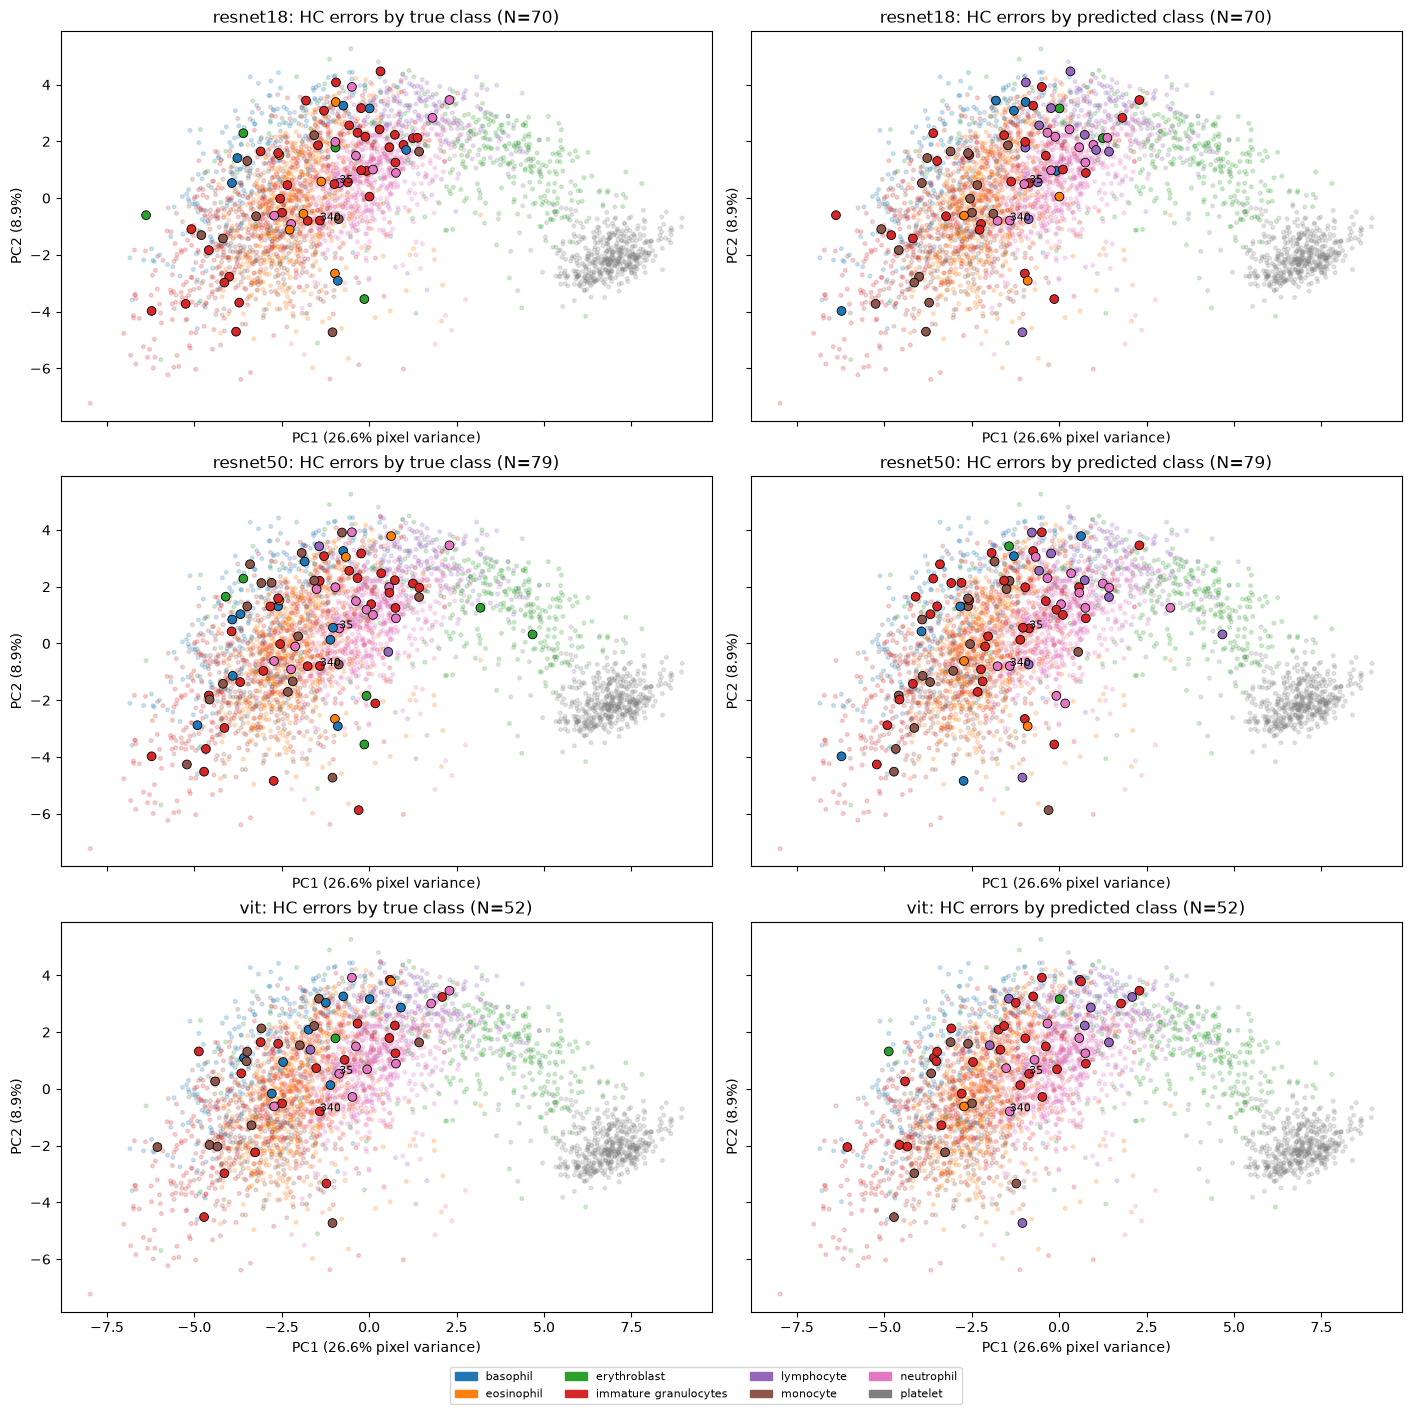

In [46]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
class_colors = plt.get_cmap('tab10')(np.arange(8))
class_cmap = ListedColormap(class_colors)
class_norm = BoundaryNorm(np.arange(9) - 0.5, 8)
xy = pca['coordinates']
fig, axes = plt.subplots(3, 2, figsize=(14, 14), sharex=True, sharey=True, layout='constrained')
for m, name in enumerate(model_names):
    ids = np.flatnonzero(pca['high_confidence_wrong'][m])
    for col, (title, colors) in enumerate([('True class', labels), ('Predicted class', predicted[m])]):
        ax = axes[m, col]
        ax.scatter(*xy.T, c=class_colors[colors], s=7, alpha=0.20)
        ax.scatter(*xy[ids].T, c=class_colors[colors[ids]], s=40, edgecolor='black', linewidth=0.6)
        for i in [340, 35]:
            if i in ids:ax.annotate(str(i), xy[i], fontsize=8)
        ax.set(title=f'{name}: HC errors by {title.lower()} (N={len(ids)})',
               xlabel=f'PC1 ({pca["explained_variance_ratio"][0]:.1%} pixel variance)',
               ylabel=f'PC2 ({pca["explained_variance_ratio"][1]:.1%})')
fig.legend(handles=[Patch(color=class_colors[c], label=class_names[c]) for c in range(8)],
           loc='outside lower center', ncol=4, fontsize=8)
plt.show()

The first two pixel PCs retain 35.6% of image variance, with PC1 strongly correlated with brightness (+0.91) and saturation (−0.90). They are therefore primarily an appearance summary, not a learned cell-class representation. The aligned views show which labels are substituted at the same image coordinates; overlap in this projection alone cannot explain why a model chose one class.

## Empirical decision-region approximation — validate the surrogate against black-box labels, not true labels

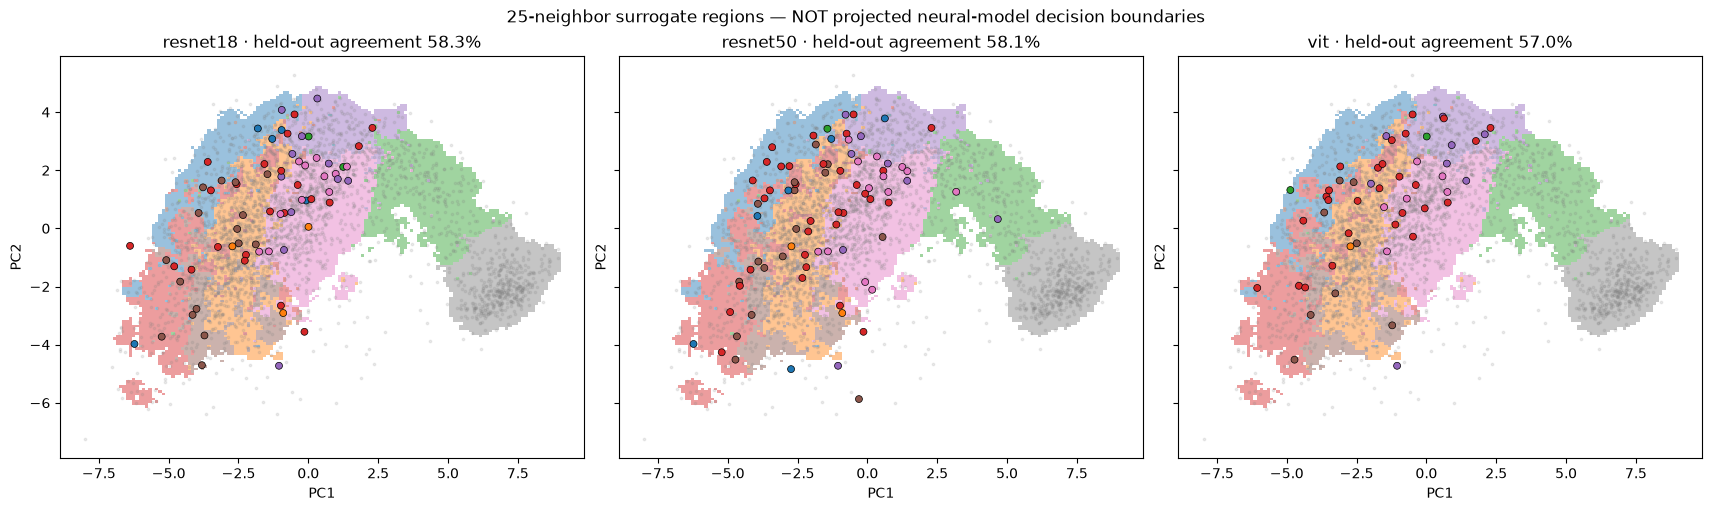

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True, layout='constrained')
for m, ax in enumerate(axes):
    region = np.ma.masked_where(~pca['support'], pca['surrogate_regions'][m])
    ax.pcolormesh(pca['grid_x'], pca['grid_y'], region, cmap=class_cmap, norm=class_norm, shading='auto', alpha=0.45)
    ids = np.flatnonzero(pca['high_confidence_wrong'][m])
    ax.scatter(*xy.T, color='gray', s=3, alpha=0.15)
    ax.scatter(*xy[ids].T, c=class_colors[predicted[m, ids]], s=25, edgecolor='black', linewidth=0.5)
    ax.set(title=f'{model_names[m]} · held-out agreement {pca["surrogate_agreement"][m]:.1%}', xlabel='PC1', ylabel='PC2')
fig.suptitle('25-neighbor surrogate regions — NOT projected neural-model decision boundaries')
plt.show()

The two-dimensional surrogate reproduces only 58.3%, 58.1% and 57.0% of held-out ResNet18, ResNet50 and ViT decisions, despite exceeding the 19–20% majority-label baseline. Much of the models’ class assignment is therefore not recoverable from this two-PC neighborhood rule. These colors are low-fidelity empirical regions in supported data areas, not the neural models’ projected boundaries; both PCA and the surrogate were refitted on the fit partition for the held-out check.

## Local black-box slices — vary two PCs around real error/control images while keeping the remaining image information fixed

In [48]:
local_path = Path('predictions/pca_blackbox_slices.npz')
if not local_path.exists():
    anchors=pca['anchor_pairs'].ravel()
    axis=np.linspace(-0.5,0.5,41)
    gx,gy=np.meshgrid(axis,axis)
    delta=np.column_stack((gx.ravel(),gy.ravel())) * np.sqrt(pca['explained_variance'])
    output=np.empty((3,len(anchors),41,41,8),dtype=np.float32)
    scores=np.empty_like(output)
    clipped=np.empty((len(anchors),41,41),dtype=np.float32)
    realized=np.empty((len(anchors),41,41,2),dtype=np.float32)
    nearest_switch=np.full((3,len(anchors)),np.nan)
    distance=np.hypot(gx,gy)
    for j,i in enumerate(anchors):
        # Keep the anchor's residual outside the first two PCs, instead of inverse-PCA mean images.
        x=images[i].reshape(-1).astype(np.float32)/255
        raw=x[None]+delta@pca['components']
        clipped[j]=((raw<0)|(raw>1)).mean(-1).reshape(41,41)
        changed=np.rint(np.clip(raw,0,1)*255).astype(np.uint8).reshape(-1,28,28,3)
        np.testing.assert_array_equal(changed[20*41+20],images[i])
        realized[j]=((changed.reshape(len(changed),-1).astype(np.float32)/255-pca['mean'])@pca['components'].T).reshape(41,41,2)
        for m,name in enumerate(model_names):
            p,logits=predict(m,changed)
            output[m,j]=p.reshape(41,41,8)
            scores[m,j]=logits.reshape(41,41,8)
            np.testing.assert_allclose(output[m,j,20,20],probabilities[m,i],atol=1e-5,rtol=1e-4)
            switched=(output[m,j].argmax(-1)!=probabilities[m,i].argmax())&(clipped[j]<=0.05)
            if switched.any():nearest_switch[m,j]=distance[switched].min()
        print(f'Anchor #{i}: all three local black-box maps complete',flush=True)
    with np.load('predictions/occlusion_test.npz',allow_pickle=False) as z:
        checkpoint_hashes=z['weight_hashes']
    np.savez_compressed('predictions/pca_blackbox_slices.npz', probabilities=output,logits=scores,
                        sample_index=anchors,anchor_pairs=pca['anchor_pairs'],labels=labels[anchors],
                        baseline_probabilities=probabilities[:,anchors],model_names=model_names,checkpoints=checkpoints,
                        weight_hashes=checkpoint_hashes,grid_x=gx,grid_y=gy,clip_fraction=clipped,
                        realized_pca_coordinates=realized,components=pca['components'],mean=pca['mean'],
                        explained_variance=pca['explained_variance'],coordinates=pca['coordinates'][anchors],
                        nearest_observed_switch=nearest_switch,seed=42,split='test',max_display_clip_fraction=0.05,
                        method='anchor plus first-two-PC displacement; original residual fixed; clip to [0,1], round to uint8',
                        axes=['model','anchor','PC2 grid row','PC1 grid column','class'])
    assert np.isfinite(output).all() and np.isfinite(scores).all()
    np.testing.assert_allclose(output.sum(-1),1,atol=1e-6)
    for m in range(3):
        exp=np.exp(scores[m].astype(float)-scores[m].max(-1,keepdims=True))
        np.testing.assert_allclose(exp/exp.sum(-1,keepdims=True),output[m],atol=2e-7,rtol=1e-5)
    print('Nearest observed label switch (PC-standard-deviation units; NaN = none on displayed grid):',nearest_switch.tolist())
    print('Fraction of each grid with <=5% clipped pixels:',(clipped<=.05).mean((1,2)).tolist())

with np.load(local_path, allow_pickle=False) as saved:
    local = {key:saved[key] for key in saved.files}
np.testing.assert_allclose(local['baseline_probabilities'], probabilities[:, local['sample_index']], atol=1e-5, rtol=1e-4)

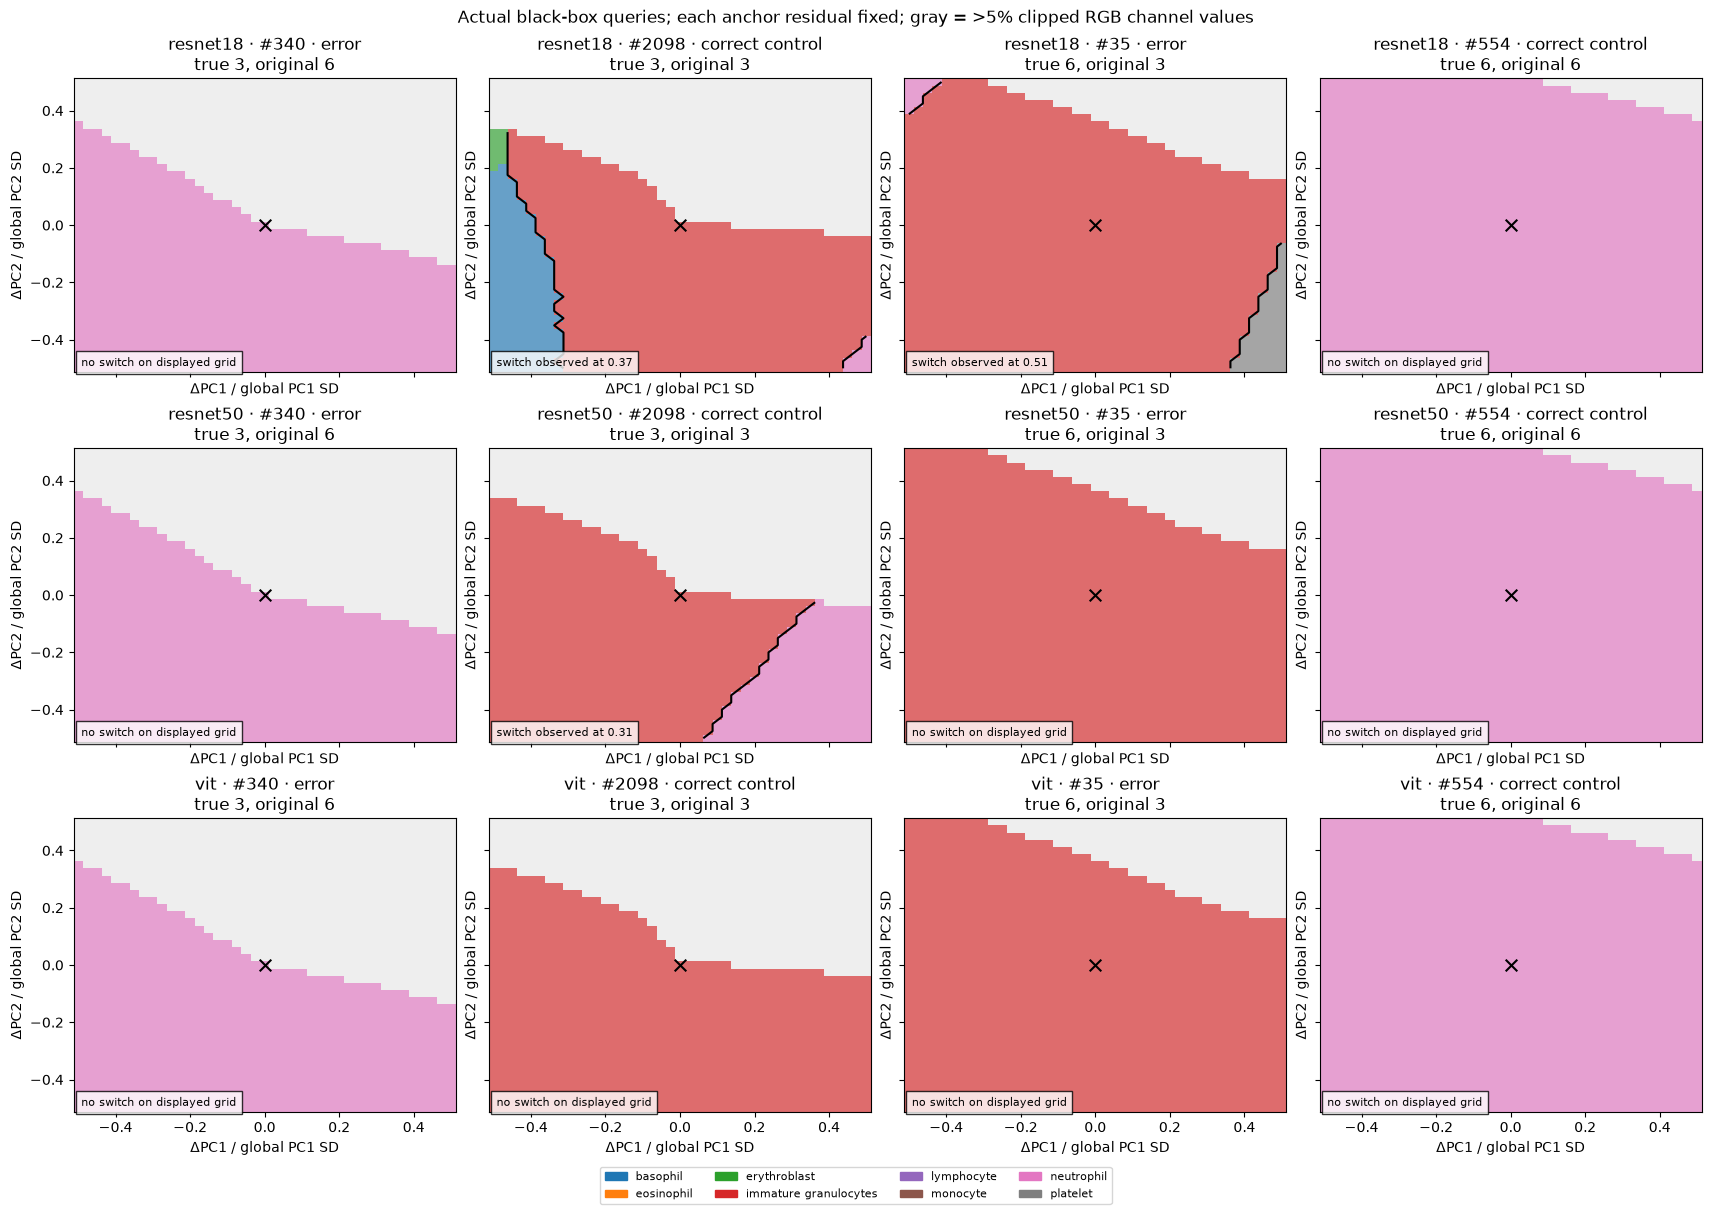

In [49]:
fig, axes = plt.subplots(3, 4, figsize=(17, 12), sharex=True, sharey=True, layout='constrained')
for m, name in enumerate(model_names):
    for j, i in enumerate(local['sample_index']):
        ax = axes[m, j]
        assigned = local['probabilities'][m, j].argmax(-1)
        invalid = local['clip_fraction'][j] > 0.05
        region = np.ma.masked_where(invalid, assigned)
        ax.set_facecolor('#eeeeee')
        ax.pcolormesh(local['grid_x'], local['grid_y'], region, cmap=class_cmap, norm=class_norm, shading='auto', alpha=0.65)
        original = local['baseline_probabilities'][m, j].argmax()
        same = np.ma.masked_where(invalid, assigned == original)
        if same.min() != same.max():ax.contour(local['grid_x'], local['grid_y'], same, levels=[0.5], colors='black')
        ax.scatter(0, 0, marker='x', color='black', s=70)
        nearest = local['nearest_observed_switch'][m, j]
        text = f'switch observed at {nearest:.2f}' if np.isfinite(nearest) else 'no switch on displayed grid'
        ax.set(title=f'{name} · #{i} · {"error" if j % 2 == 0 else "correct control"}\ntrue {labels[i]}, original {original}',
               xlabel='ΔPC1 / global PC1 SD', ylabel='ΔPC2 / global PC2 SD')
        ax.text(0.02, 0.02, text, transform=ax.transAxes, fontsize=8, bbox={'facecolor':'white','alpha':0.8})
fig.legend(handles=[Patch(color=class_colors[c], label=class_names[c]) for c in range(8)],
           loc='outside lower center', ncol=4, fontsize=8)
fig.suptitle('Actual black-box queries; each anchor residual fixed; gray = >5% clipped RGB channel values')
plt.show()

Shared high-confidence error #340 has no observed label switch for any model within the displayed slice, whereas its correct control #2098 crosses a boundary for both CNNs. Across the twelve model/anchor combinations, only three have an admitted switch, so these examples do not support the hypothesis that confident errors must lie closer to a boundary along the leading pixel PCs. Each map conditions on a different fixed residual; gray regions exceed the clipping limit, and absence of a switch on this finite grid is not a global robustness certificate.

## C · Linking errors to stability — same brightness and translation levels; all HC errors versus RGB-near correct ≥90%-confident same-class controls; a changed decision is not necessarily a correction

In [50]:
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    followup_levels = {kind: saved[f'levels_{kind}'] for kind in ['brightness', 'translation']}
followup = dict(model_names=model_names, threshold=threshold, common_wrong=common_wrong, common_hc=common_hc,
                gallery_pairs=gallery_pairs, class_sizes=class_sizes, class_hc_counts=class_hc_counts,
                cohort_names=cohort_names, cohort_effects=cohort_effects, cohort_weights=np.stack(cohort_weights),
                cohort_roles=['HC errors', 'correct HC controls'], checkpoints=checkpoints)
for m, ids in enumerate(error_ids):
    controls = neighbor_ids[m][0]
    assert correct[m, controls].all() and (confidence[m, controls] >= threshold).all()
    np.testing.assert_array_equal(labels[controls], labels[ids])
    selected = np.stack((ids, controls))
    base = probabilities[m, selected]
    scores = np.load(f'predictions/{model_names[m]}_test.npz')['logits'][selected]
    original = base.argmax(-1)
    original_probability = base.max(-1)
    followup[f'{model_names[m]}_ids'] = selected
    followup[f'{model_names[m]}_exclusive_hc'] = exclusive_hc[m]
    followup[f'{model_names[m]}_baseline'] = base
    followup[f'{model_names[m]}_baseline_logits'] = scores.reshape(2, len(ids), 8)
    print(f'{model_names[m]}: {len(ids)} errors, {len(np.unique(controls))} unique controls; mean baseline confidence {original_probability[0].mean():.1%} / {original_probability[1].mean():.1%}')
    for col, (kind, values) in enumerate(followup_levels.items()):
        with np.load('predictions/stability.npz', allow_pickle=False) as saved:
            p = saved[kind][m, :, 0][:, selected].transpose(1, 0, 2, 3)
            logits = saved[f'logits_{kind}'][m, :, 0][:, selected].transpose(1, 0, 2, 3)
        delta = np.take_along_axis(p, original[:, None, :, None], axis=-1)[..., 0] - original_probability[:, None]
        followup[f'{model_names[m]}_{kind}'] = p
        followup[f'{model_names[m]}_{kind}_logits'] = logits
        print(f'{model_names[m]} {kind}: mean probability drop for errors {-delta[0].mean():.3f}, controls {-delta[1].mean():.3f}')
followup.update({f'levels_{kind}': values for kind, values in followup_levels.items()})
np.savez_compressed('predictions/high_confidence_followup.npz', **followup)

def plot_targeted_followup():
    fig, axes = plt.subplots(3, 2, figsize=(13, 10), layout='constrained')
    for m, model in enumerate(model_names):
        ids = followup[f'{model}_ids'][0]
        base = followup[f'{model}_baseline']
        original, original_probability = base.argmax(-1), base.max(-1)
        for col, (kind, values) in enumerate(followup_levels.items()):
            p = followup[f'{model}_{kind}']
            delta = np.take_along_axis(p, original[:, None, :, None], axis=-1)[..., 0] - original_probability[:, None]
            for role, name in enumerate(['HC errors', 'Correct HC controls']):
                axes[m, col].plot(values, delta[role].mean(-1), 'o-', label=name)
            axes[m, col].axhline(0, color='gray', ls='--')
            axes[m, col].set(title=f'{model_names[m]} · {kind} · N={len(ids)} pairs',
                              xlabel=kind, ylabel='Change in p(original class)')
            axes[m, col].grid(alpha=0.2)
    axes[0, 0].legend()
    fig.suptitle('Targeted follow-up using stability levels: errors versus class-matched correct decisions')
    plt.show()

resnet18: 70 errors, 67 unique controls; mean baseline confidence 97.6% / 99.6%
resnet18 brightness: mean probability drop for errors 0.528, controls 0.370
resnet18 translation: mean probability drop for errors 0.390, controls 0.120
resnet50: 79 errors, 75 unique controls; mean baseline confidence 97.9% / 99.2%
resnet50 brightness: mean probability drop for errors 0.356, controls 0.298
resnet50 translation: mean probability drop for errors 0.369, controls 0.197
vit: 52 errors, 50 unique controls; mean baseline confidence 97.0% / 99.4%
vit brightness: mean probability drop for errors 0.105, controls 0.028
vit translation: mean probability drop for errors 0.078, controls 0.033


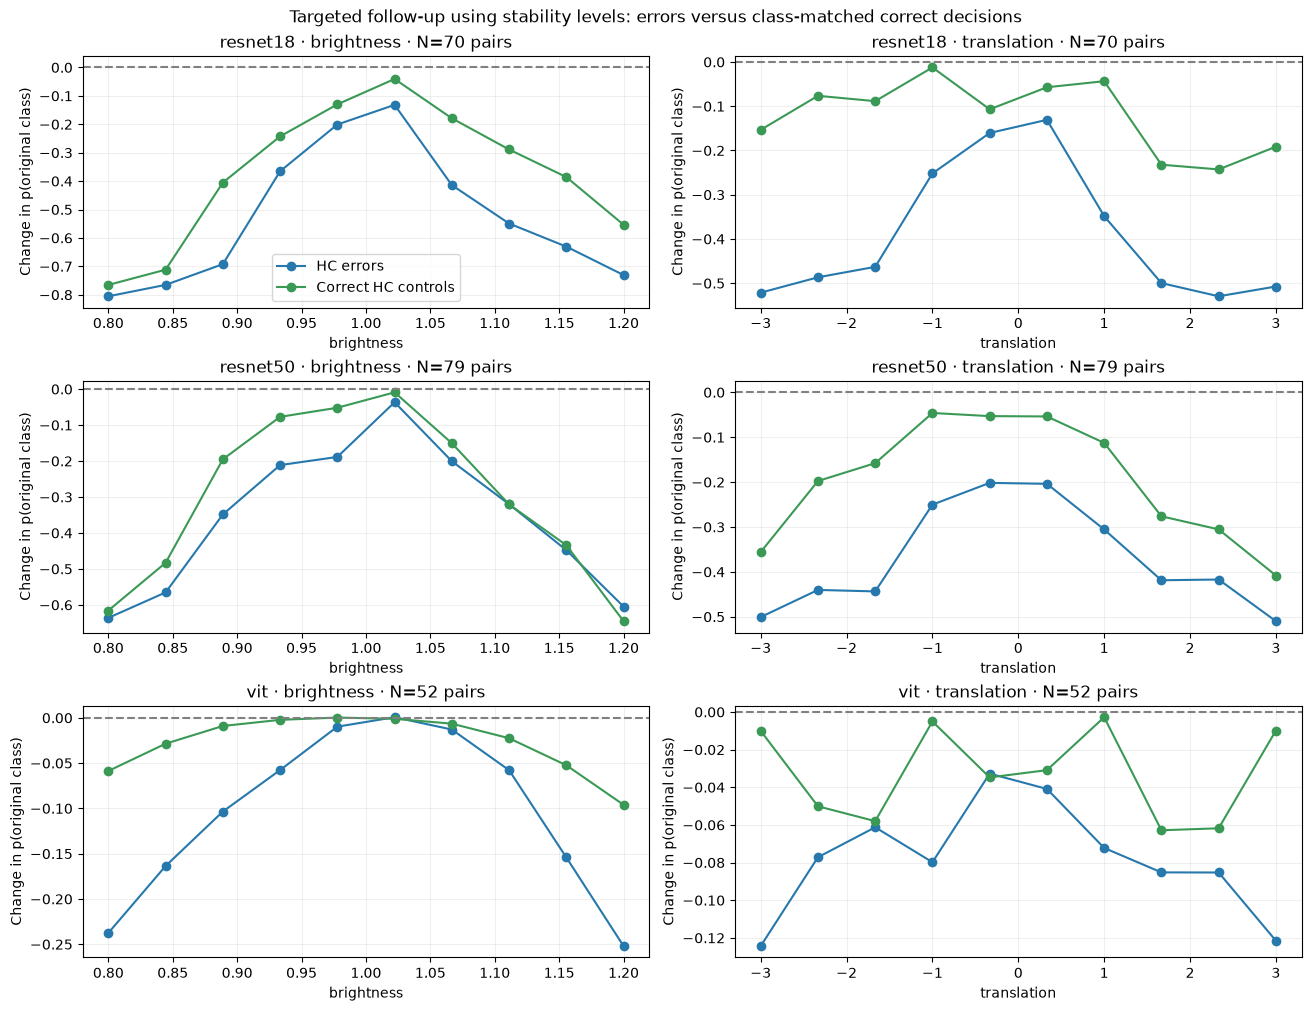

In [51]:
plot_targeted_followup()

The high-confidence wrong decisions lose more original-class probability than the correct controls under both tested operations in all three models. For ResNet18, the mean translation drop is 39.0 percentage points for errors versus 12.0 for controls, despite both groups starting above the 90% threshold. Transformation response may therefore be worth testing as an additional warning signal, but the controls start with higher average confidence and a changed prediction is not necessarily a correction.

## Findings

- **Shared class substitutions (gallery A):** All models misclassify 39 test images; 18 receive ≥90% confidence from every model. On those 18 they select the same wrong class, with nine substitutions between immature granulocytes and neutrophils. This identifies repeated class competition, rather than independent random mistakes, while exclusive errors show that the checkpoints do not share every weakness.
- **Class and color dependence (class rates and saturation):** ResNet18 has its highest HC-error rate among immature granulocytes (6.22%); monocytes are highest for ResNet50 (5.63%) and ViT (4.58%). Desaturation sends almost all CNN error and correct-control images to erythroblast, despite matched true-class composition. This is a class-attractor response to appearance changes, not evidence that saturation adjustment specifically resolves the original error mechanism.
- **Appearance association versus decision geometry (features and PCA):** Shared HC errors are brighter (+0.70 control SD), have higher blue values (+0.74 SD) and lower saturation (−0.55 SD). Yet two pixel PCs, dominated by appearance variation, reproduce only 57–58% of held-out model labels through the surrogate. Local queries also leave error #340 unchanged while its correct control crosses for both CNNs, so neither global PCA position nor closeness to a leading-PC boundary explains these errors in general.
- **Spatial support for wrong decisions (population and matched occlusion):** Full-test maps show central dependence, but its relation to errors varies by class: ResNet50’s central wrong-minus-correct difference is positive for monocytes and negative for basophils. Restricting to HC errors and paired same-class HC-correct controls gives extra central drops of 0.104, 0.098 and 0.113 for ResNet18, ResNet50 and ViT. This isolates differential support for the original decisions without interpreting fixed image patches as annotated cell structures.
- **Direction-specific instability (targeted stability):** Across the tested brightness and translation levels, the HC-error groups lose more original-class probability than their correct controls. ResNet18’s mean translation drop is 39.0 versus 12.0 percentage points. Together with the largely constant local PCA slices, this shows why the chosen perturbation direction matters; high confidence does not imply either uniformly fragile or uniformly stable decisions.

**Limits:** Test-only exploratory analysis, not independent confirmation of selected hypotheses. Paired intervention controls match true class and confidence threshold, not exact confidence; some are reused. Feature-distribution controls are class-weighted. ResNet18/ViT resize to 224×224 whereas ResNet50 uses 28×28, with different resizing methods. Color features are correlated; modified images may leave the data distribution or change the label. PCA slices use selected cases, a finite grid and clipping, not a global decision-boundary reconstruction.
